# C02m — Sentence moments and residual detector contributions
Run after C02l. Inputs are completed C02j unique-controlled rewrites, never punctuation-edited outputs. Same-genre, length-matched human references are frozen from C02l. Only cases supported for all four sentence statistics are edited.

Conservative punctuation-only splits, merges, and paired split+merge boundary shifts preserve the ordered lowercase alphabetic token sequence and word lengths. Thus CPW and unique-word share remain fixed; this is **sentence correction, not lexical CPW correction**. Parse eligibility and local language-model likelihood do not guarantee semantic fidelity: inspect text_pairs.csv/manual_review.csv.

The objective is summed normalized distance outside the four Q20–Q60 bands. Already satisfied dimensions must remain satisfied. No edit-count budget; stop on success or no eligible improving candidate. Report partial progress, never claim guaranteed target attainment. Candidate ranking uses the existing sigmoid mutability threshold (exploratory settings). Final ranking is mean frozen-tree contribution minus matched-human contribution, not a green/purple change heatmap. Matching remains fixed before/after; intervals bootstrap cases and are descriptive pointwise intervals.


In [1]:
IMPLEMENTATION_HASH='e3d58709b0c7fb1d252e80f7433dff35171439857ece1668e03c9f24ba3c4453'
from pathlib import Path
import json, math, time, hashlib, os, re, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import spacy, torch
from transformers import AutoTokenizer, AutoModelForCausalLM
ROOT=Path('..')
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR=ROOT/'results/causal/C02e2_raid_feature_guided'
SOURCE=ROOT/'results/causal/C02j_fz118_residual_30'
OUT=ROOT/'results/causal/C02m_sentence_moments'
OUT.mkdir(parents=True,exist_ok=True)
SCORER_ID='openai-community/gpt2'
SCORER_REVISION='main'
LEFT_WORDS=48; RIGHT_WORDS=32
BAR_MIN=.05; BAR_MAX=.95; SLOPE=4.; MIDPOINT=1.
REF = ROOT/'results/causal/C02l_human_length_references'
SENT_METRICS = ['wps_mean','wps_var','cps_mean','cps_var']
METRICS = SENT_METRICS + ['cpw_mean','cpw_var']
nlp=spacy.load('en_core_web_sm')
def normalize(t): return t.replace('\n',' ').replace('\r',' ')
def digest(v): return hashlib.sha256(json.dumps(v,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def save(path,v):
    tmp=path.with_suffix('.tmp'); tmp.write_text(json.dumps(v,indent=2)); os.replace(tmp,path)
def bar(q): return BAR_MIN+(BAR_MAX-BAR_MIN)/(1+math.exp(max(-60,min(60,SLOPE*(q-MIDPOINT)))))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def measure(doc):
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    tokens = [t for t in doc if t.is_alpha]
    seqs = {
        'wps': [sum(t.is_alpha for t in s) for s in sentences],
        'cps': [len(s.text.strip()) for s in sentences],
        'cpw': [len(t.text) for t in tokens],
    }
    W, S, C = len(tokens), len(sentences), len(doc.text)
    result = {'W':W, 'S':S, 'C':C,
              'detector_C_over_W': C/W if W else np.nan,
              'detector_C_over_S': C/S if S else np.nan,
              'share_unique_words': len({t.text.lower() for t in tokens})/W if W else np.nan}
    for name, seq in seqs.items():
        a = np.asarray(seq, dtype=float)
        result[name+'_mean'] = float(a.mean()) if len(a) else np.nan
        result[name+'_var'] = float(a.var(ddof=0)) if len(a) else np.nan
    return result, seqs


bounds=pd.read_csv(REF/'matched_human_quantiles.csv')
matched=pd.read_csv(REF/'matched_human_joint_moments.csv')
manifest=pd.read_csv(SOURCE/'selection_30.csv')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert corpus.source_id.is_unique
text_map=corpus.set_index('source_id').text.to_dict()
source_contract=json.loads((SOURCE/'frozen_contract.json').read_text())
source_hash=digest(source_contract)
cases=[]; exclusions=[]
for row in manifest.to_dict('records'):
    case_id=row['case_id']
    b=bounds.loc[(bounds.case_id==case_id)&bounds.metric.isin(SENT_METRICS)].set_index('metric')
    if str(row['domain']).lower()=='poetry' or len(b)!=4 or not b.supported.eq(True).all():
        exclusions.append(dict(case_id=case_id,reason='poetry_or_insufficient_reference_support'));continue
    payload=json.loads((SOURCE/case_id/'controlled/state.json').read_text())
    assert payload['contract_hash']==source_hash
    state=payload['state'];assert state['finished'] and state['status']=='completed_eos'
    text=normalize(state['committed_text'])
    stats,_=measure(nlp(text))
    for m in SENT_METRICS: assert np.isclose(stats[m],b.loc[m,'controlled_value']), (case_id,m)
    refs=matched.loc[matched.case_id==case_id,'source_id'].tolist()
    assert refs and len(refs)==len(set(refs))
    cases.append(dict(case_id=case_id,domain=row['domain'],text=text,reference_ids=refs,
        bounds={m:{'low':float(b.loc[m,'q20']),'high':float(b.loc[m,'q60'])} for m in SENT_METRICS}))
assert cases, 'No supported cases. Run C02l first.'
pd.DataFrame(exclusions).to_csv(OUT/'excluded_cases.csv',index=False)
print('Supported cases:',len(cases),'Excluded:',len(exclusions))


Supported cases: 15 Excluded: 15


In [3]:
tokenizer=AutoTokenizer.from_pretrained(SCORER_ID,revision=SCORER_REVISION,use_fast=True)
model=AutoModelForCausalLM.from_pretrained(SCORER_ID,revision=SCORER_REVISION)
device='cuda' if torch.cuda.is_available() else 'cpu';model.to(device).eval()
# Score at most the model context; reject overflow rather than silently truncating.
@torch.inference_mode()
def continuation_score(left,tail):
    enc=tokenizer(left+tail,return_offsets_mapping=True,return_tensors='pt',add_special_tokens=False)
    offsets=enc.pop('offset_mapping')[0].tolist();ids=enc['input_ids'].to(device)
    if ids.shape[1]<2 or ids.shape[1]>model.config.max_position_embeddings:return None
    logp=model(input_ids=ids).logits[0,:-1].log_softmax(-1)
    chosen=logp.gather(1,ids[0,1:,None]).squeeze(1)
    mask=torch.tensor([end>len(left) for start,end in offsets[1:]],device=device)
    return float(chosen[mask].mean()) if mask.any() else None

def score_edit(text,e):
    a,b,replacement=e['start'],e['end'],e['replacement']
    left_parts=list(re.finditer(r'\S+',text[:a]));right_parts=list(re.finditer(r'\S+',text[b:]))
    left=text[left_parts[-LEFT_WORDS].start() if len(left_parts)>=LEFT_WORDS else 0:a]
    right=text[b:b+(right_parts[RIGHT_WORDS-1].end() if len(right_parts)>=RIGHT_WORDS else len(text)-b)]
    # Fixed flanks shared by both alternatives; future text contributes to each score.
    before=continuation_score(left,text[a:b]+right);after=continuation_score(left,replacement+right)
    if before is None or after is None:return None
    return dict(mutability=math.exp(min(0.,after-before)),score_before=before,score_after=after)

contract=dict(cases=cases,source_contract_hash=source_hash,scorer=SCORER_ID,
    revision=getattr(model.config,'_commit_hash',None),spacy=nlp.meta,
    parameters=[LEFT_WORDS,RIGHT_WORDS,BAR_MIN,BAR_MAX,SLOPE,MIDPOINT],
    implementation='sentence-moments-v1')
CONTRACT_HASH=digest(contract)
if (OUT/'contract.json').exists():
    assert digest(json.loads((OUT/'contract.json').read_text()))==CONTRACT_HASH, 'Changed inputs/settings: use a new OUT.'
else: save(OUT/'contract.json',contract)


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 11653.25it/s]


In [4]:
def independent(text):
    d=nlp(text.strip())
    return any(t.dep_=='ROOT' and t.pos_ in {'VERB','AUX'} and
               any(c.dep_ in {'nsubj','nsubjpass','csubj','expl'} for c in t.children) for t in d)

def signature(text):
    return [(t.text.lower(),len(t.text)) for t in nlp.make_doc(text) if t.is_alpha]

def apply_ops(text,ops):
    for a,b,r in sorted(ops,reverse=True):text=text[:a]+r+text[b:]
    return text

def proposals(text):
    doc=nlp(text); sentences=[s for s in doc.sents if any(t.is_alpha for t in s)]
    splits=[]; merges=[]
    for s in sentences:
        for t in s:
            if t.text not in {';',','}:continue
            if t.text==',' and not re.match(r'\s+(?:and|but|yet|so)\b', text[t.idx+1:s.end_char], re.I):continue
            left=text[s.start_char:t.idx];right=text[t.idx+1:s.end_char]
            if independent(left) and independent(right):
                # Capitalize the first alphabetic character after the new boundary.
                match=re.search(r'[A-Za-z]',right)
                if match:
                    j=t.idx+1+match.start()
                    splits.append([(t.idx,t.idx+1,'.'),(j,j+1,text[j].upper())])
    for a,b in zip(sentences,sentences[1:]):
        # Restrict merging to plain periods between two independent clauses.
        end=a.end_char
        if text[end-1:end]!='.' or text[end:b.start_char].strip():continue
        if independent(a.text[:-1]) and independent(b.text):
            merges.append([(end-1,end,';')])
    out=[('split',o) for o in splits]+[('merge',o) for o in merges]
    for a in splits:
        for b in merges:
            if all(x[1]<=y[0] or y[1]<=x[0] for x in a for y in b):
                out.append(('boundary_shift',a+b))
    seen=set()
    for rule,ops in out:
        candidate=apply_ops(text,ops)
        if candidate not in seen:
            seen.add(candidate);yield rule,ops,candidate

def distances(stats,b):
    return np.array([max(b[m]['low']-stats[m],0,stats[m]-b[m]['high']) /
        max(b[m]['high']-b[m]['low'],1.0) for m in SENT_METRICS])

def run_case(c):
    text=c['text']; audit=[]; initial_sig=signature(text)
    stats,_=measure(nlp(text));initial=stats.copy(); seen={text}
    while True:
        before_d=distances(stats,c['bounds']); loss=float(before_d.sum())
        if loss<=1e-12: status='in_band';break
        threshold=bar(float(before_d.max()))
        accepted=[]; checked=0
        for rule,ops,candidate in proposals(text):
            checked+=1
            if candidate in seen or signature(candidate)!=initial_sig:continue
            after,_=measure(nlp(candidate))
            expected_delta={'split':1,'merge':-1,'boundary_shift':0}[rule]
            if after['S']!=stats['S']+expected_delta or after['S']<2:continue
            d=distances(after,c['bounds'])
            if np.any((before_d<=1e-12)&(d>1e-12)) or d.sum()>=loss-1e-10:continue
            a=min(o[0] for o in ops); b=max(o[1] for o in ops)
            replacement=apply_ops(text[a:b],[(x-a,y-a,r) for x,y,r in ops])
            score=score_edit(text,dict(start=a,end=b,replacement=replacement))
            if score is None or score['mutability']<threshold:continue
            accepted.append((score['mutability'],loss-float(d.sum()),rule,ops,candidate,after,score))
        if not accepted:status='no_eligible_improving_candidate';break
        accepted.sort(key=lambda x:(-x[0],-x[1],x[2],x[4]))
        mut,gain,rule,ops,candidate,after,score=accepted[0]
        audit.append(dict(step=len(audit)+1,rule=rule,ops=ops,before=stats,after=after,
            objective_before=loss,objective_after=loss-gain,threshold=threshold,**score))
        text=candidate;stats=after;seen.add(text)
        print(c['case_id'],len(audit),rule,'loss=',round(loss-gain,4),flush=True)
    assert signature(text)==initial_sig
    for m in ['cpw_mean','cpw_var','share_unique_words']:
        assert np.isclose(stats[m],initial[m],atol=1e-12)
    return dict(text=text,status=status,audit=audit,initial=initial,final=stats,contract_hash=CONTRACT_HASH)

results=[]
for c in cases:
    path=OUT/(c['case_id']+'.json')
    if path.exists():
        state=json.loads(path.read_text());assert state['contract_hash']==CONTRACT_HASH
    else:
        print('Starting',c['case_id'],flush=True);state=run_case(c);save(path,state)
    results.append((c,state))
review=pd.DataFrame([dict(case_id=c['case_id'],domain=c['domain'],before=c['text'],after=s['text'],
    status=s['status'],n_edits=len(s['audit'])) for c,s in results])
review.to_csv(OUT/'text_pairs.csv',index=False)
if not (OUT/'manual_review.csv').exists():
    review.assign(meaning_preserved='',grammar_acceptable='',notes='').to_csv(OUT/'manual_review.csv',index=False)
moment_rows=[]
for c,s in results:
    for cond,stats in [('unique_only',s['initial']),('sentence_corrected',s['final'])]:
        moment_rows.append(dict(case_id=c['case_id'],condition=cond,**stats,
            objective=float(distances(stats,c['bounds']).sum())))
pd.DataFrame(moment_rows).to_csv(OUT/'sentence_moment_outcomes.csv',index=False)
display(review[['case_id','status','n_edits']])
display(pd.DataFrame(moment_rows))


Starting raid_residual_03
Starting raid_residual_05
Starting raid_residual_09
Starting raid_residual_10
raid_residual_10 1 boundary_shift loss= 0.0
Starting raid_residual_14
raid_residual_14 1 boundary_shift loss= 0.9495
Starting raid_residual_16
Starting raid_residual_17
raid_residual_17 1 split loss= 0.0
Starting raid_residual_18
raid_residual_18 1 merge loss= 0.0
Starting raid_residual_19
Starting raid_residual_21
Starting raid_residual_24
Starting raid_residual_25
Starting raid_residual_26
Starting raid_residual_27
Starting raid_residual_29


,case_id,status,n_edits
0,raid_residual_03,no_eligible_improving_candidate,0
1,raid_residual_05,no_eligible_improving_candidate,0
2,raid_residual_09,no_eligible_improving_candidate,0
3,raid_residual_10,in_band,1
4,raid_residual_14,no_eligible_improving_candidate,1
5,raid_residual_16,no_eligible_improving_candidate,0
6,raid_residual_17,in_band,1
7,raid_residual_18,in_band,1
8,raid_residual_19,no_eligible_improving_candidate,0
9,raid_residual_21,no_eligible_improving_candidate,0


,case_id,condition,W,S,C,detector_C_over_W,detector_C_over_S,share_unique_words,wps_mean,wps_var,cps_mean,cps_var,cpw_mean,cpw_var,objective
0,raid_residual_03,unique_only,218,11,1285,5.894495,116.818182,0.577982,19.818182,13.785124,115.000000,275.454545,4.651376,6.759195,1.667139
1,raid_residual_03,sentence_corrected,218,11,1285,5.894495,116.818182,0.577982,19.818182,13.785124,115.000000,275.454545,4.651376,6.759195,1.667139
2,raid_residual_05,unique_only,302,21,1992,6.596026,94.857143,0.460265,14.380952,95.378685,93.333333,4878.412698,4.960265,5.051401,0.350174
3,raid_residual_05,sentence_corrected,302,21,1992,6.596026,94.857143,0.460265,14.380952,95.378685,93.333333,4878.412698,4.960265,5.051401,0.350174
4,raid_residual_09,unique_only,145,6,1003,6.917241,167.166667,0.744828,24.166667,33.805556,166.333333,1917.888889,5.751724,9.110773,0.923759
5,raid_residual_09,sentence_corrected,145,6,1003,6.917241,167.166667,0.744828,24.166667,33.805556,166.333333,1917.888889,5.751724,9.110773,0.923759
6,raid_residual_10,unique_only,263,12,1615,6.140684,134.583333,0.589354,21.916667,25.909722,133.416667,1128.243056,4.961977,7.435817,1.144128
7,raid_residual_10,sentence_corrected,263,12,1615,6.140684,134.583333,0.589354,21.916667,48.909722,133.416667,1731.909722,4.961977,7.435817,0.000000
8,raid_residual_14,unique_only,130,7,765,5.884615,109.285714,0.646154,18.571429,44.816327,108.428571,1686.530612,4.776923,7.081006,1.048610
9,raid_residual_14,sentence_corrected,130,7,765,5.884615,109.285714,0.646154,18.571429,71.387755,108.428571,2219.102041,4.776923,7.081006,0.949503


In [5]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

condition,sentence_corrected,unique_only,change
case_id,,,
raid_residual_03,0.477969,0.615016,-0.137047
raid_residual_05,0.660272,0.660272,0.000000
raid_residual_09,0.452777,0.452777,0.000000
raid_residual_10,0.361022,0.550788,-0.189766
raid_residual_14,0.507570,0.478645,0.028925
raid_residual_16,0.563365,0.563365,0.000000
raid_residual_17,0.404901,0.541417,-0.136515
raid_residual_18,0.326342,0.537928,-0.211586
raid_residual_19,0.500481,0.551039,-0.050558


,before_gap,corrected_gap,ci_low,ci_high,fraction_AIward,before_rank,corrected_rank
punct_relative_colon,0.009643,0.010723,0.002059,0.020922,0.600000,3,1
punct_relative_hyphen,0.009687,0.009092,0.004746,0.014211,0.933333,2,2
punct_per_sentence_colon,0.007126,0.007474,0.001751,0.014154,0.533333,7,3
punct_per_sentence_hyphen,0.007450,0.007261,0.003778,0.011012,0.866667,6,4
pos_1gram_overlap_bin_9,0.006261,0.006694,0.001767,0.011311,0.733333,12,5
share_google_top100,0.006279,0.006634,0.002536,0.011202,0.800000,11,6
punct_per_sentence_period,0.006437,0.006527,0.003579,0.009132,0.800000,10,7
punct_relative_comma,0.006993,0.006054,0.002670,0.009567,0.800000,8,8
share_long_words,0.005850,0.005650,0.002944,0.008515,0.866667,13,9
pos_3gram_overlap_bin_0,0.007830,0.005625,0.001303,0.009645,0.933333,5,10


,before_gap,corrected_gap,ci_low,ci_high,fraction_AIward,before_rank,corrected_rank
share_unique_words,0.004499,0.004471,0.000058,0.009876,0.6,25,22


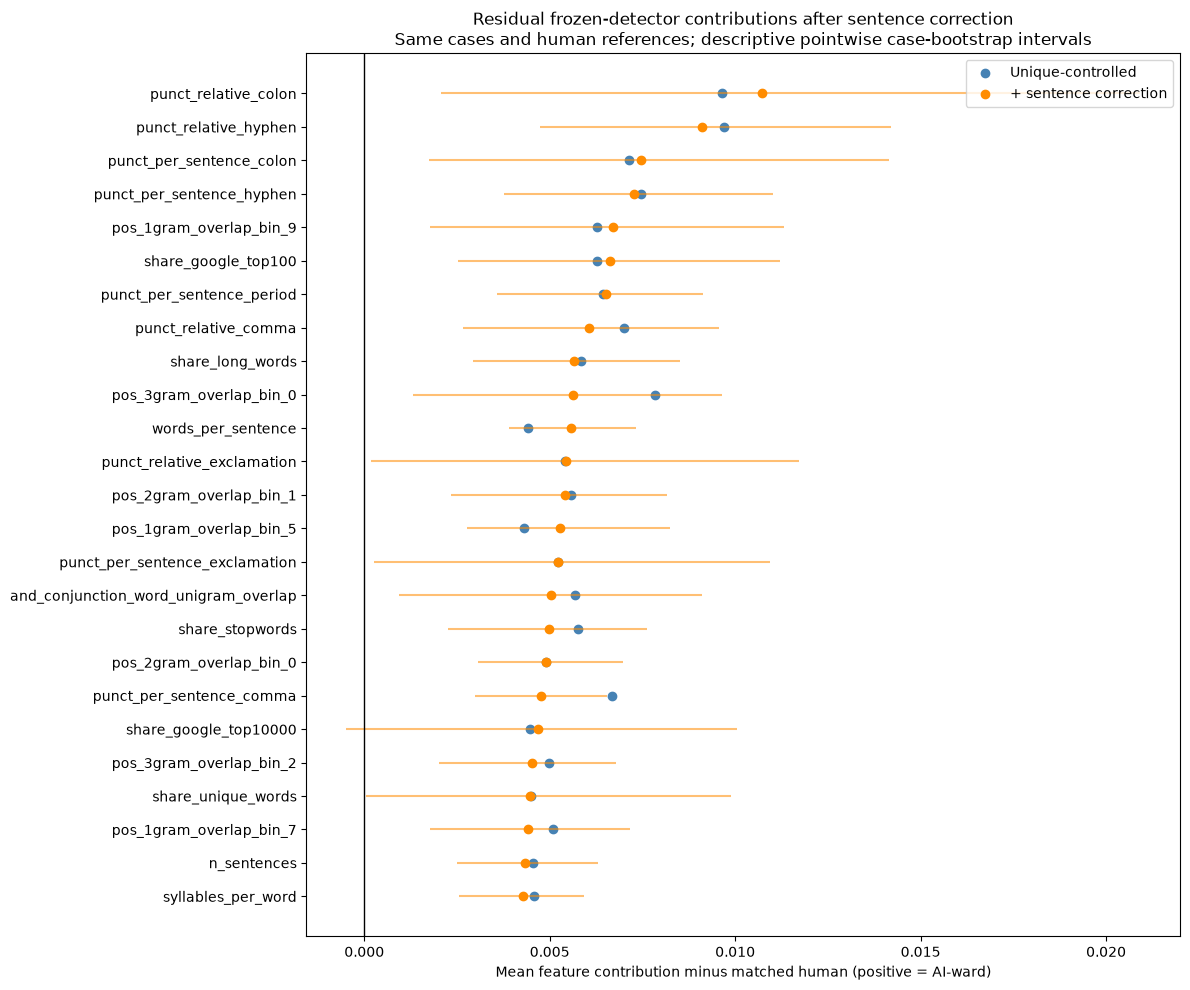

Ranks are within this supported subset, not directly comparable to the earlier 30-case ranks.
Saved to ../results/causal/C02m_sentence_moments_v2


In [9]:
# Exact tree-path contributions, summed across the frozen forest.
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
def contributions(X):
    a=np.asarray(X,dtype=np.float32); output=np.zeros_like(a,dtype=float);bias=0.
    for estimator in detector.estimators_:
        tree=estimator.tree_; value=tree.value[:,0,:].astype(float)
        prob=value[:,1]/value.sum(axis=1);bias+=prob[0]/len(detector.estimators_)
        for i,row in enumerate(a):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if row[feature]<=tree.threshold[node] else tree.children_right[node]
                output[i,feature]+=(prob[child]-prob[node])/len(detector.estimators_)
                node=child
    assert np.allclose(bias+output.sum(axis=1),detector.predict_proba(X)[:,1],atol=1e-8)
    return output
human_ids=sorted({r for c in cases for r in c['reference_ids']})
human_frame=pd.DataFrame([extract_fz118(normalize(text_map[r])) for r in human_ids],index=human_ids,columns=FEATURE_NAMES)
human_contrib=pd.DataFrame(contributions(human_frame[model_features]),index=human_ids,columns=model_features)
rows=[];vec=[]
for c,s in results:
    for cond,t in [('unique_only',c['text']),('sentence_corrected',s['text'])]:
        rows.append(dict(case_id=c['case_id'],condition=cond));vec.append(extract_fz118(normalize(t)))
index=pd.MultiIndex.from_frame(pd.DataFrame(rows))
frame=pd.DataFrame(vec,index=index,columns=FEATURE_NAMES)
frame.to_csv(OUT/'all_feature_values.csv')
contrib=pd.DataFrame(contributions(frame[model_features]),index=index,columns=model_features)
contrib.to_csv(OUT/'tree_contributions.csv')
scores=pd.Series(detector.predict_proba(frame[model_features])[:,1],index=index).unstack('condition')
scores['change']=scores.sentence_corrected-scores.unique_only
scores.to_csv(OUT/'detector_scores.csv');display(scores)
gaps={}
for cond in ['unique_only','sentence_corrected']:
    gaps[cond]=pd.DataFrame([contrib.loc[(c['case_id'],cond)].values-
        human_contrib.loc[c['reference_ids']].mean().values for c in cases],
        index=[c['case_id'] for c in cases],columns=model_features)
    gaps[cond].to_csv(OUT/f'{cond}_human_contribution_gaps.csv')
rng=np.random.default_rng(2026)
a=gaps['sentence_corrected'].to_numpy()
boot=np.array([a[rng.integers(0,len(a),len(a))].mean(axis=0) for _ in range(2000)])
ranking=pd.DataFrame({'before_gap':gaps['unique_only'].mean(),
    'corrected_gap':gaps['sentence_corrected'].mean(),
    'ci_low':np.quantile(boot,.025,axis=0),'ci_high':np.quantile(boot,.975,axis=0),
    'fraction_AIward':(gaps['sentence_corrected']>0).mean()})
ranking['before_rank']=ranking.before_gap.rank(ascending=False,method='min').astype(int)
ranking=ranking.sort_values('corrected_gap',ascending=False)
ranking['corrected_rank']=np.arange(1,len(ranking)+1)
ranking.to_csv(OUT/'residual_feature_ranking.csv')
display(ranking.head(25))
if 'share_unique_words' in ranking.index:display(ranking.loc[['share_unique_words']])
top=ranking.head(25).iloc[::-1]
fig,ax=plt.subplots(figsize=(12,10))
y=np.arange(len(top))
ax.hlines(y,top.ci_low,top.ci_high,color='darkorange',alpha=.55)
ax.scatter(top.before_gap,y,label='Unique-controlled',color='steelblue')
ax.scatter(top.corrected_gap,y,label='+ sentence correction',color='darkorange')
ax.axvline(0,color='black',lw=1)
ax.set_yticks(y,top.index);ax.legend()
ax.set_xlabel('Mean feature contribution minus matched human (positive = AI-ward)')
ax.set_title('Residual frozen-detector contributions after sentence correction\nSame cases and human references; descriptive pointwise case-bootstrap intervals')
fig.tight_layout();fig.savefig(OUT/'residual_contribution_ranking.png',dpi=180,bbox_inches='tight');plt.show()
print('Ranks are within this supported subset, not directly comparable to the earlier 30-case ranks.')
print('Saved to',OUT)


In [7]:
# Diagnose existing stopping points without modifying the corrected texts.
from collections import Counter

DIAG = OUT / "diagnostics_v1"
DIAG.mkdir(parents=True, exist_ok=True)

def inspect_opportunities(text):
    sentences = [
        s for s in nlp(text).sents
        if any(t.is_alpha for t in s)
    ]
    opportunities, splits, merges = [], [], []

    def record(rule, position, left, right, reason):
        opportunities.append(dict(
            rule=rule, position=position,
            left=left, right=right, reason=reason
        ))

    def parser_reason(left_ok, right_ok):
        if not left_ok and not right_ok:
            return "parser_both_failed"
        return "parser_left_failed" if not left_ok else "parser_right_failed"

    for s in sentences:
        for t in s:
            if t.text not in {";", ","}:
                continue

            left = text[s.start_char:t.idx]
            right = text[t.idx + 1:s.end_char]

            if t.text == "," and not re.match(
                r"\s+(?:and|but|yet|so)\b", right, re.I
            ):
                record("split", t.idx, left, right,
                       "comma_not_allowed_coordination")
                continue

            left_ok, right_ok = independent(left), independent(right)
            if not (left_ok and right_ok):
                record("split", t.idx, left, right,
                       parser_reason(left_ok, right_ok))
                continue

            match = re.search(r"[A-Za-z]", right)
            if match is None:
                record("split", t.idx, left, right,
                       "no_capitalizable_character")
                continue

            j = t.idx + 1 + match.start()
            splits.append([
                (t.idx, t.idx + 1, "."),
                (j, j + 1, text[j].upper())
            ])
            record("split", t.idx, left, right, "eligible_primitive")

    for a, b in zip(sentences, sentences[1:]):
        end = a.end_char

        if text[end - 1:end] != "." or text[end:b.start_char].strip():
            record("merge", end - 1, a.text, b.text,
                   "not_plain_period_boundary")
            continue

        left_ok = independent(a.text[:-1])
        right_ok = independent(b.text)
        if not (left_ok and right_ok):
            record("merge", end - 1, a.text, b.text,
                   parser_reason(left_ok, right_ok))
            continue

        merges.append([(end - 1, end, ";")])
        record("merge", end - 1, a.text, b.text, "eligible_primitive")

    raw = (
        [("split", ops) for ops in splits]
        + [("merge", ops) for ops in merges]
    )
    raw += [
        ("boundary_shift", a + b)
        for a in splits
        for b in merges
        if all(
            x[1] <= y[0] or y[1] <= x[0]
            for x in a for y in b
        )
    ]

    candidates, seen = [], set()
    for rule, ops in raw:
        candidate = apply_ops(text, ops)
        if candidate not in seen:
            seen.add(candidate)
            candidates.append((rule, ops, candidate))

    # Check that instrumentation matches the actual proposal generator.
    assert {
        (rule, candidate) for rule, ops, candidate in candidates
    } == {
        (rule, candidate) for rule, ops, candidate in proposals(text)
    }, "Diagnostic templates differ from the current proposals() implementation."

    return opportunities, candidates


opportunity_rows, candidate_rows, summaries = [], [], []

for c, state in results:
    if state["status"] == "in_band":
        summaries.append(dict(
            case_id=c["case_id"],
            status=state["status"],
            diagnosed=False
        ))
        continue

    assert state["contract_hash"] == CONTRACT_HASH
    text = state["text"]
    before, _ = measure(nlp(text))
    before_d = distances(before, c["bounds"])
    loss = float(before_d.sum())
    threshold = bar(float(before_d.max()))
    original_signature = signature(c["text"])

    seen = {c["text"]}
    replay = c["text"]
    for edit in state["audit"]:
        replay = apply_ops(replay, edit["ops"])
        seen.add(replay)
    assert replay == text, "Cannot reconstruct accepted trajectory."

    opportunities, candidates = inspect_opportunities(text)
    opportunity_rows.extend(
        dict(case_id=c["case_id"], **row)
        for row in opportunities
    )

    counts = Counter()
    for number, (rule, ops, candidate) in enumerate(candidates):
        after, _ = measure(nlp(candidate))
        after_d = distances(after, c["bounds"])
        gain = loss - float(after_d.sum())

        violations = [
            metric
            for metric, old, new in zip(
                SENT_METRICS, before_d, after_d
            )
            if old <= 1e-12 and new > 1e-12
        ]
        expected_delta = {
            "split": 1, "merge": -1, "boundary_shift": 0
        }[rule]

        # Record the FIRST failed check, matching run_case().
        reason = None
        if candidate in seen:
            reason = "already_visited"
        elif signature(candidate) != original_signature:
            reason = "word_signature_changed"
        elif after["S"] != before["S"] + expected_delta:
            reason = "unexpected_sentence_count"
        elif after["S"] < 2:
            reason = "fewer_than_two_sentences"
        elif violations:
            reason = "breaks_satisfied_band"
        elif gain <= 1e-10:
            reason = "no_joint_objective_improvement"

        score = {}
        if reason is None:
            a = min(op[0] for op in ops)
            b = max(op[1] for op in ops)
            replacement = apply_ops(
                text[a:b],
                [(x - a, y - a, r) for x, y, r in ops]
            )
            scored = score_edit(
                text,
                dict(start=a, end=b, replacement=replacement)
            )
            if scored is None:
                reason = "likelihood_unscorable"
            else:
                score = scored
                reason = (
                    "below_mutability_threshold"
                    if score["mutability"] < threshold
                    else "would_be_accepted"
                )

        counts[reason] += 1
        candidate_rows.append(dict(
            case_id=c["case_id"],
            candidate_id=number,
            rule=rule,
            reason=reason,
            objective_before=loss,
            objective_after=float(after_d.sum()),
            gain=gain,
            breaks_satisfied_band=",".join(violations),
            threshold=threshold,
            mutability=score.get("mutability", np.nan),
            score_before=score.get("score_before", np.nan),
            score_after=score.get("score_after", np.nan),
            ops=json.dumps(ops),
            before_text=text,
            candidate_text=candidate,
            **{"before_" + m: before[m] for m in SENT_METRICS},
            **{"after_" + m: after[m] for m in SENT_METRICS}
        ))

    summaries.append(dict(
        case_id=c["case_id"],
        status=state["status"],
        diagnosed=True,
        objective=loss,
        threshold=threshold,
        n_opportunities=len(opportunities),
        n_eligible_primitives=sum(
            row["reason"] == "eligible_primitive"
            for row in opportunities
        ),
        n_candidates=len(candidates),
        **counts
    ))
    print(
        c["case_id"],
        "| candidates:", len(candidates),
        "|", dict(counts),
        flush=True
    )

diagnostic_summary = pd.DataFrame(summaries)
opportunity_frame = pd.DataFrame(opportunity_rows)
candidate_columns = [
    "case_id", "candidate_id", "rule", "reason", "gain",
    "objective_before", "objective_after", "breaks_satisfied_band",
    "threshold", "mutability", "score_before", "score_after",
    "ops", "before_text", "candidate_text"
]
diagnostic_candidates = (
    pd.DataFrame(candidate_rows)
    if candidate_rows
    else pd.DataFrame(columns=candidate_columns)
)

diagnostic_summary.to_csv(
    DIAG / "case_rejection_summary.csv", index=False
)
opportunity_frame.to_csv(
    DIAG / "primitive_opportunities.csv", index=False
)
diagnostic_candidates.to_csv(
    DIAG / "candidate_rejections.csv", index=False
)

# "Best" = greatest objective improvement, not verified text quality.
rejected = diagnostic_candidates.loc[
    diagnostic_candidates.reason != "would_be_accepted"
]
best_rejected = (
    rejected.sort_values(
        ["case_id", "reason", "gain", "candidate_id"],
        ascending=[True, True, False, True]
    )
    .groupby(["case_id", "reason"], sort=False)
    .head(3)
)
best_rejected.to_csv(
    DIAG / "best_rejected_candidates.csv", index=False
)

with pd.option_context(
    "display.max_rows", None, "display.max_columns", None
):
    display(diagnostic_summary)

    if len(opportunity_frame):
        print("\nTemplate/parser checks:")
        display(
            opportunity_frame.groupby(["rule", "reason"])
            .size().rename("opportunities").to_frame()
        )

    if len(diagnostic_candidates):
        print("\nCandidate rejection checks:")
        display(
            diagnostic_candidates.groupby(["rule", "reason"])
            .size().rename("candidates").to_frame()
        )
        print("\nTop rejected candidates per case and rejection reason:")
        display(best_rejected[[
            "case_id", "rule", "reason", "gain",
            "breaks_satisfied_band", "mutability", "threshold"
        ]])

# Print one candidate per unresolved case for manual inspection.
for row in (
    best_rejected.sort_values("gain", ascending=False)
    .groupby("case_id", sort=True).head(1)
    .to_dict("records")
):
    print(
        "\n", row["case_id"], row["rule"], row["reason"],
        "| objective gain:", round(row["gain"], 4)
    )
    print("BEFORE:\n" + row["before_text"])
    print("PROPOSED:\n" + row["candidate_text"])

if (diagnostic_candidates.reason == "would_be_accepted").any():
    print(
        "\nDIAGNOSTIC MISMATCH: an eligible improvement exists at a "
        "stored stopping point. Check code/model consistency before tuning."
    )

print("\nCounts identify the first failed check.")
print("Likelihood NaN = not evaluated or unscorable.")
print("Zero candidates means no candidate under the current templates.")
print("Saved diagnostics:", DIAG)

raid_residual_03 | candidates: 0 | {}
raid_residual_05 | candidates: 0 | {}
raid_residual_09 | candidates: 11 | {'breaks_satisfied_band': 9, 'no_joint_objective_improvement': 2}
raid_residual_14 | candidates: 20 | {'breaks_satisfied_band': 14, 'no_joint_objective_improvement': 6}
raid_residual_16 | candidates: 7 | {'no_joint_objective_improvement': 1, 'below_mutability_threshold': 6}
raid_residual_19 | candidates: 0 | {}
raid_residual_21 | candidates: 0 | {}
raid_residual_24 | candidates: 7 | {'below_mutability_threshold': 4, 'breaks_satisfied_band': 3}
raid_residual_25 | candidates: 7 | {'breaks_satisfied_band': 7}
raid_residual_27 | candidates: 1 | {'breaks_satisfied_band': 1}
raid_residual_29 | candidates: 0 | {}


,case_id,status,diagnosed,objective,threshold,n_opportunities,n_eligible_primitives,n_candidates,breaks_satisfied_band,no_joint_objective_improvement,below_mutability_threshold
0,raid_residual_03,no_eligible_improving_candidate,True,1.667139,0.527317,16.0,0.0,0.0,NaN,NaN,NaN
1,raid_residual_05,no_eligible_improving_candidate,True,0.350174,0.887735,49.0,0.0,0.0,NaN,NaN,NaN
2,raid_residual_09,no_eligible_improving_candidate,True,0.923759,0.790747,13.0,6.0,11.0,9.0,2.0,NaN
3,raid_residual_10,in_band,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,raid_residual_14,no_eligible_improving_candidate,True,0.949503,0.739503,10.0,8.0,20.0,14.0,6.0,NaN
5,raid_residual_16,no_eligible_improving_candidate,True,0.417921,0.908097,24.0,7.0,7.0,NaN,1.0,6.0
6,raid_residual_17,in_band,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,raid_residual_18,in_band,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,raid_residual_19,no_eligible_improving_candidate,True,1.163087,0.797187,26.0,0.0,0.0,NaN,NaN,NaN
9,raid_residual_21,no_eligible_improving_candidate,True,1.398643,0.399051,20.0,0.0,0.0,NaN,NaN,NaN



Template/parser checks:


opportunities
rule  reason                                       
merge eligible_primitive                         33
      not_plain_period_boundary                  58
      parser_both_failed                         17
      parser_left_failed                          3
      parser_right_failed                         3
split comma_not_allowed_coordination            137
      eligible_primitive                          3
      parser_both_failed                          3
      parser_left_failed                          2
      parser_right_failed                         7


Candidate rejection checks:


candidates
rule           reason                                    
boundary_shift breaks_satisfied_band                   13
               no_joint_objective_improvement           4
merge          below_mutability_threshold              10
               breaks_satisfied_band                   18
               no_joint_objective_improvement           5
split          breaks_satisfied_band                    3


Top rejected candidates per case and rejection reason:


,case_id,rule,reason,gain,breaks_satisfied_band,mutability,threshold
0,raid_residual_09,split,breaks_satisfied_band,-0.322150,"wps_var,cps_var",NaN,0.790747
2,raid_residual_09,merge,breaks_satisfied_band,-3.520523,cps_var,NaN,0.790747
6,raid_residual_09,boundary_shift,breaks_satisfied_band,-3.768025,"wps_var,cps_var",NaN,0.790747
7,raid_residual_09,boundary_shift,no_joint_objective_improvement,0.000000,,NaN,0.790747
1,raid_residual_09,merge,no_joint_objective_improvement,-3.426785,,NaN,0.790747
11,raid_residual_14,split,breaks_satisfied_band,0.713966,"wps_var,cps_var",NaN,0.739503
12,raid_residual_14,split,breaks_satisfied_band,0.606765,"wps_var,cps_var",NaN,0.739503
27,raid_residual_14,boundary_shift,breaks_satisfied_band,-0.044558,wps_var,NaN,0.739503
21,raid_residual_14,boundary_shift,no_joint_objective_improvement,0.000000,,NaN,0.739503
24,raid_residual_14,boundary_shift,no_joint_objective_improvement,0.000000,,NaN,0.739503



 raid_residual_14 split breaks_satisfied_band | objective gain: 0.714
BEFORE:
I returned to my dorm after lunch and discovered that someone had emptied all the segregated waste bins, mixing compost and recycling with regular trash. This is particularly wasteful since my school does not compost or recycle; The bins had been overturned, and the hazardous waste was dangerous for the workers who had to collect it. I hope it was the fundamentalists in my dorm who did this, as they have complained about "lack of faith-based living" in the dorms. These people are the absolute worst. I received an email from the university president about the university's apology for this injustice. And the residential life staff are deflecting the criticism. I feel so bad for the workers who have to deal with the literal medical waste from this situation.
PROPOSED:
I returned to my dorm after lunch and discovered that someone had emptied all the segregated waste bins, mixing compost and recycling with regula

In [8]:
# C02m v2: broader sentence candidates + joint improvement.
# Theta settings unchanged. Original C02m outputs remain available.
import difflib
import html
from IPython.display import HTML, display

PREVIOUS_OUT = OUT
OUT = ROOT / "results/causal/C02m_sentence_moments_v2"
OUT.mkdir(parents=True, exist_ok=True)

# Accept explicit subjects attached to verbal OR copular predicates.
def independent(text):
    doc = nlp(text.strip())
    subjects = {"nsubj", "nsubjpass", "csubj", "csubjpass", "expl"}
    for token in doc:
        if token.dep_ != "ROOT":
            continue
        children = list(token.children)
        predicate = (
            token.pos_ in {"VERB", "AUX"}
            or any(child.dep_ == "cop" for child in children)
        )
        if predicate and any(child.dep_ in subjects for child in children):
            return True
    return False


def proposals(text):
    doc = nlp(text)
    sentences = [
        s for s in doc.sents if any(t.is_alpha for t in s)
    ]
    splits, merges = [], []

    def capitalize_right(start, end):
        """Capitalize the first alphabetic token without altering its length."""
        right = text[start:end]
        parsed = nlp.make_doc(right)
        token = next((t for t in parsed if t.is_alpha), None)
        if token is None:
            return None
        position = start + token.idx
        replacement = text[position].upper()
        if len(replacement) != 1:
            return None
        return (position, position + 1, replacement)

    def emit_split(sentence, start, end, replacement):
        left = text[sentence.start_char:start]
        right = text[end:sentence.end_char]
        if not (independent(left) and independent(right)):
            return

        capitalization = capitalize_right(end, sentence.end_char)
        if capitalization is None:
            return

        ops = [(start, end, replacement)]
        if text[capitalization[0]:capitalization[1]] != capitalization[2]:
            ops.append(capitalization)
        splits.append(ops)

    for sentence in sentences:
        tokens = list(sentence)

        # Existing semicolons and commas between independent clauses.
        # Clause eligibility, rather than a conjunction whitelist, decides.
        for token in tokens:
            if token.text in {";", ","}:
                emit_split(
                    sentence, token.idx, token.idx + len(token.text), "."
                )

        # Coordination without an existing comma:
        # "She arrived and he left." -> "She arrived. And he left."
        # Preserve the conjunction and all alphabetic words.
        for token in tokens:
            if token.pos_ != "CCONJ":
                continue
            if token.text.lower() not in {"and", "but", "yet", "so", "or", "nor"}:
                continue

            start = token.idx
            while start > sentence.start_char and text[start - 1].isspace():
                start -= 1

            # Existing comma/semicolon cases were handled above.
            if start == token.idx or (
                start > sentence.start_char
                and text[start - 1] in ",;"
            ):
                continue

            emit_split(sentence, start, start, ".")
            # Insertion occurs before existing whitespace; it remains intact.

    for left_sentence, right_sentence in zip(sentences, sentences[1:]):
        gap = text[left_sentence.end_char:right_sentence.start_char]
        if gap.strip():
            continue

        # A period followed by a closing quote/bracket can still be the
        # sentence boundary. Preserve those closing characters.
        left_text = left_sentence.text
        match = re.search(r"""\.(["”’')\]]*)\s*$""", left_text)
        if match is None:
            continue

        period = left_sentence.start_char + match.start()
        if not (
            independent(text[left_sentence.start_char:period])
            and independent(right_sentence.text)
        ):
            continue

        closers = match.group(1)
        if closers:
            # Move the separator outside closing punctuation.
            # These candidates still require reparse and likelihood checks.
            ops = [(period, period + 1 + len(closers), closers + ";")]
        else:
            ops = [(period, period + 1, ";")]

        merges.append(ops)

    raw = (
        [("split", ops) for ops in splits]
        + [("merge", ops) for ops in merges]
    )

    # A combined split and merge changes sentence-length dispersion
    # while retaining sentence count.
    for split_ops in splits:
        for merge_ops in merges:
            if all(
                a[1] <= b[0] or b[1] <= a[0]
                for a in split_ops
                for b in merge_ops
            ):
                raw.append(("boundary_shift", split_ops + merge_ops))

    seen = {text}
    for rule, ops in raw:
        candidate = apply_ops(text, ops)
        if candidate not in seen:
            seen.add(candidate)
            yield rule, ops, candidate


def run_case(c):
    text = c["text"]
    initial_signature = signature(text)
    stats, _ = measure(nlp(text))
    initial = stats.copy()
    seen = {text}
    audit = []
    stopping_checks = {}

    while True:
        before_d = distances(stats, c["bounds"])
        loss = float(before_d.sum())

        if loss <= 1e-12:
            status = "in_band"
            break

        threshold = bar(float(before_d.max()))
        accepted = []
        counts = Counter()

        for rule, ops, candidate in proposals(text):
            counts["proposed"] += 1

            if candidate in seen:
                counts["already_visited"] += 1
                continue
            if signature(candidate) != initial_signature:
                counts["word_signature_changed"] += 1
                continue

            after, _ = measure(nlp(candidate))
            expected = {"split": 1, "merge": -1, "boundary_shift": 0}[rule]
            if after["S"] != stats["S"] + expected:
                counts["unexpected_sentence_count"] += 1
                continue
            if after["S"] < 2:
                counts["fewer_than_two_sentences"] += 1
                continue

            after_d = distances(after, c["bounds"])
            gain = loss - float(after_d.sum())

            # V2: allow trade-offs between dimensions, but require a strict
            # decrease in the same combined objective.
            if gain <= 1e-10:
                counts["no_joint_objective_improvement"] += 1
                continue

            start = min(op[0] for op in ops)
            end = max(op[1] for op in ops)
            replacement = apply_ops(
                text[start:end],
                [(a - start, b - start, r) for a, b, r in ops]
            )
            score = score_edit(
                text,
                dict(start=start, end=end, replacement=replacement)
            )

            if score is None:
                counts["likelihood_unscorable"] += 1
                continue
            if score["mutability"] < threshold:
                counts["below_mutability_threshold"] += 1
                continue

            counts["eligible"] += 1
            accepted.append((
                score["mutability"], gain, rule, ops,
                candidate, after, score
            ))

        stopping_checks = dict(counts)
        if not accepted:
            status = "no_eligible_improving_candidate"
            break

        # Preserve the existing mutability-first selection policy.
        accepted.sort(key=lambda x: (-x[0], -x[1], x[2], x[4]))
        mutability, gain, rule, ops, candidate, after, score = accepted[0]

        newly_outside = [
            metric
            for metric, old, new in zip(
                SENT_METRICS, before_d, distances(after, c["bounds"])
            )
            if old <= 1e-12 and new > 1e-12
        ]
        audit.append(dict(
            step=len(audit) + 1,
            rule=rule,
            ops=ops,
            before=stats,
            after=after,
            objective_before=loss,
            objective_after=loss - gain,
            newly_outside=newly_outside,
            threshold=threshold,
            checks=dict(counts),
            **score
        ))

        text, stats = candidate, after
        seen.add(text)
        print(
            c["case_id"], "| edit", len(audit), rule,
            "| objective", round(loss - gain, 4),
            "| newly outside:", newly_outside,
            flush=True
        )

    assert signature(text) == initial_signature
    for metric in ["cpw_mean", "cpw_var", "share_unique_words"]:
        assert np.isclose(stats[metric], initial[metric], atol=1e-12)

    return dict(
        text=text, status=status, audit=audit,
        initial=initial, final=stats,
        stopping_checks=stopping_checks,
        contract_hash=CONTRACT_HASH
    )


# Freeze the experiment separately. Capture executable rule definitions,
# including constants, so changing this cell invalidates cached results.
import marshal
import hashlib

implementation_digest = hashlib.sha256(
    b"".join(
        marshal.dumps(fn.__code__)
        for fn in [
            independent, proposals, run_case, apply_ops,
            measure, signature, distances, score_edit,
            continuation_score, bar
        ]
    )
).hexdigest()

contract = dict(
    cases=cases,
    source_contract_hash=source_hash,
    scorer=SCORER_ID,
    revision=getattr(model.config, "_commit_hash", None),
    spacy=nlp.meta,
    parameters=[
        LEFT_WORDS, RIGHT_WORDS,
        BAR_MIN, BAR_MAX, SLOPE, MIDPOINT
    ],
    implementation="sentence-moments-v2",
    implementation_digest=implementation_digest,
    objective="strict_joint_improvement_without_satisfied_band_lock"
)
CONTRACT_HASH = digest(contract)

contract_path = OUT / "contract.json"
if contract_path.exists():
    assert digest(json.loads(contract_path.read_text())) == CONTRACT_HASH, (
        "V2 settings/code changed. Choose a new OUT directory."
    )
else:
    save(contract_path, contract)

results = []
for c in cases:
    path = OUT / (c["case_id"] + ".json")
    if path.exists():
        state = json.loads(path.read_text())
        assert state["contract_hash"] == CONTRACT_HASH
    else:
        print("Starting", c["case_id"], flush=True)
        state = run_case(c)
        save(path, state)
    results.append((c, state))

review = pd.DataFrame([
    dict(
        case_id=c["case_id"], domain=c["domain"],
        before=c["text"], after=s["text"],
        status=s["status"], n_edits=len(s["audit"])
    )
    for c, s in results
])
review.to_csv(OUT / "text_pairs.csv", index=False)

if not (OUT / "manual_review.csv").exists():
    review.assign(
        meaning_preserved="", grammar_acceptable="", notes=""
    ).to_csv(OUT / "manual_review.csv", index=False)

moment_rows, stopping_rows = [], []
for c, state in results:
    for condition, stats in [
        ("unique_only", state["initial"]),
        ("sentence_corrected", state["final"])
    ]:
        moment_rows.append(dict(
            case_id=c["case_id"], condition=condition, **stats,
            objective=float(distances(stats, c["bounds"]).sum())
        ))
    stopping_rows.append(dict(
        case_id=c["case_id"],
        status=state["status"],
        **state.get("stopping_checks", {})
    ))

pd.DataFrame(moment_rows).to_csv(
    OUT / "sentence_moment_outcomes.csv", index=False
)
pd.DataFrame(stopping_rows).to_csv(
    OUT / "stopping_checks.csv", index=False
)

display(review[["case_id", "status", "n_edits"]])
display(pd.DataFrame(stopping_rows).fillna(0))


# Wrapped local character diffs for every accepted edit.
def show_local_diff(before, after, title, context=100):
    matcher = difflib.SequenceMatcher(
        None, before, after, autojunk=False
    )
    blocks = []

    for group in matcher.get_grouped_opcodes(context):
        old_parts, new_parts = [], []
        for tag, a, b, x, y in group:
            old = html.escape(before[a:b])
            new = html.escape(after[x:y])
            if tag == "equal":
                old_parts.append(old)
                new_parts.append(new)
            else:
                if old:
                    old_parts.append(
                        '<mark style="background:#ffd9d9">' + old + "</mark>"
                    )
                if new:
                    new_parts.append(
                        '<mark style="background:#d9edff">' + new + "</mark>"
                    )
        blocks.append(
            "<b>Before:</b> …" + "".join(old_parts)
            + "…<br><b>After:</b> …" + "".join(new_parts) + "…"
        )

    display(HTML(
        '<div style="white-space:pre-wrap;overflow-wrap:anywhere;'
        'line-height:1.6;margin:14px 0">'
        "<b>" + html.escape(title) + "</b><br>"
        + "<br><br>".join(blocks) + "</div>"
    ))

for c, state in results:
    current = c["text"]
    for edit in state["audit"]:
        updated = apply_ops(current, edit["ops"])
        show_local_diff(
            current, updated,
            f"{c['case_id']} | edit {edit['step']} | {edit['rule']} | "
            f"objective {edit['objective_before']:.4f}"
            f" → {edit['objective_after']:.4f}"
        )
        current = updated
    assert current == state["text"]

print("Saved V2 results:", OUT)
print("Now rerun the existing feature-extraction and residual-ranking cells.")
print("The old diagnostic cell targets V1 templates; do not rerun it with V2.")

Starting raid_residual_03
raid_residual_03 | edit 1 split | objective 1.3852 | newly outside: ['wps_mean', 'cps_mean']
raid_residual_03 | edit 2 boundary_shift | objective 0.8051 | newly outside: []
raid_residual_03 | edit 3 boundary_shift | objective 0.6442 | newly outside: []
raid_residual_03 | edit 4 boundary_shift | objective 0.3754 | newly outside: []
raid_residual_03 | edit 5 merge | objective 0.2059 | newly outside: ['wps_var']
Starting raid_residual_05
Starting raid_residual_09
Starting raid_residual_10
raid_residual_10 | edit 1 boundary_shift | objective 1.1089 | newly outside: []
raid_residual_10 | edit 2 split | objective 0.8813 | newly outside: []
raid_residual_10 | edit 3 boundary_shift | objective 0.1015 | newly outside: []
raid_residual_10 | edit 4 boundary_shift | objective 0.0021 | newly outside: []
raid_residual_10 | edit 5 boundary_shift | objective 0.0 | newly outside: []
Starting raid_residual_14
raid_residual_14 | edit 1 split | objective 0.2355 | newly outside: [

,case_id,status,n_edits
0,raid_residual_03,no_eligible_improving_candidate,5
1,raid_residual_05,no_eligible_improving_candidate,0
2,raid_residual_09,no_eligible_improving_candidate,0
3,raid_residual_10,in_band,5
4,raid_residual_14,no_eligible_improving_candidate,1
5,raid_residual_16,no_eligible_improving_candidate,0
6,raid_residual_17,in_band,3
7,raid_residual_18,in_band,5
8,raid_residual_19,in_band,2
9,raid_residual_21,no_eligible_improving_candidate,0


,case_id,status,proposed,already_visited,no_joint_objective_improvement,unexpected_sentence_count,below_mutability_threshold,eligible
0,raid_residual_03,no_eligible_improving_candidate,35.0,2.0,28.0,4.0,1.0,0.0
1,raid_residual_05,no_eligible_improving_candidate,3.0,0.0,2.0,0.0,1.0,0.0
2,raid_residual_09,no_eligible_improving_candidate,23.0,0.0,22.0,0.0,1.0,0.0
3,raid_residual_10,in_band,55.0,1.0,39.0,0.0,12.0,3.0
4,raid_residual_14,no_eligible_improving_candidate,23.0,0.0,15.0,0.0,8.0,0.0
5,raid_residual_16,no_eligible_improving_candidate,23.0,0.0,4.0,1.0,18.0,0.0
6,raid_residual_17,in_band,26.0,1.0,17.0,0.0,2.0,6.0
7,raid_residual_18,in_band,27.0,1.0,17.0,0.0,1.0,8.0
8,raid_residual_19,in_band,95.0,0.0,61.0,16.0,6.0,12.0
9,raid_residual_21,no_eligible_improving_candidate,0.0,0.0,0.0,0.0,0.0,0.0


Saved V2 results: ../results/causal/C02m_sentence_moments_v2
Now rerun the existing feature-extraction and residual-ranking cells.
The old diagnostic cell targets V1 templates; do not rerun it with V2.


Using 15 cases in all four panels.


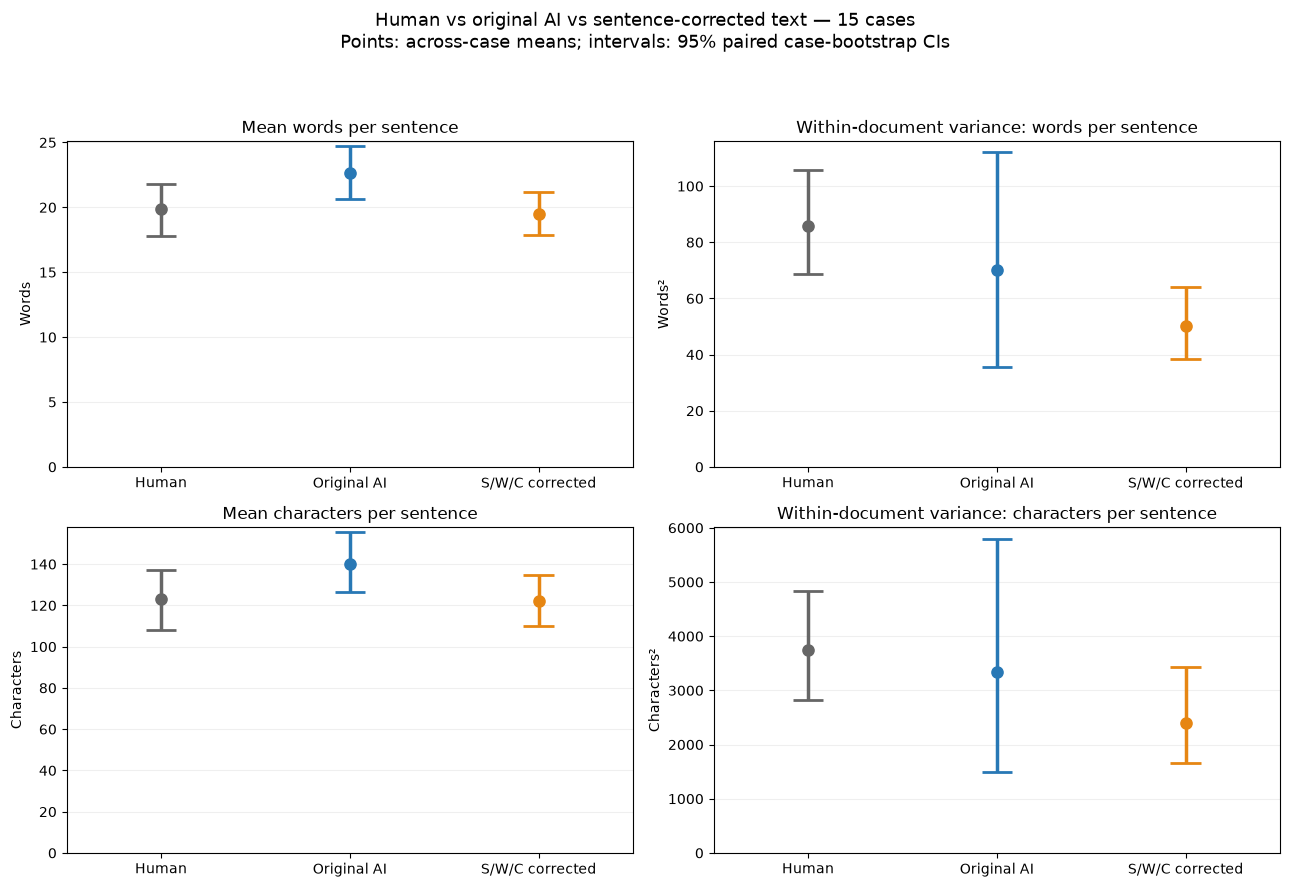

,metric,condition,mean,ci_low,ci_high,n_cases
0,wps_mean,Human,19.8728,17.7974,21.7990,15
1,wps_mean,Original AI,22.6756,20.6563,24.7454,15
2,wps_mean,S/W/C corrected,19.5024,17.8507,21.1590,15
3,wps_var,Human,85.8389,68.5966,105.6671,15
4,wps_var,Original AI,70.2801,35.6676,112.1676,15
5,wps_var,S/W/C corrected,50.1905,38.4936,64.0290,15
6,cps_mean,Human,123.1046,108.0359,136.9927,15
7,cps_mean,Original AI,140.2993,126.5690,155.4973,15
8,cps_mean,S/W/C corrected,122.1468,110.2055,134.7540,15
9,cps_var,Human,3752.5188,2818.6265,4840.5375,15


,metric,comparison,mean_difference,ci_low,ci_high
0,wps_mean,Original AI minus Human,2.8028,0.6480,5.0397
1,wps_mean,Corrected minus Human,-0.3704,-1.6644,1.1897
2,wps_mean,Corrected minus Original AI,-3.1732,-5.2082,-1.4629
3,wps_var,Original AI minus Human,-15.5588,-45.0963,19.1093
4,wps_var,Corrected minus Human,-35.6484,-47.4615,-24.6297
5,wps_var,Corrected minus Original AI,-20.0895,-54.1770,9.0948
6,cps_mean,Original AI minus Human,17.1947,2.3634,32.3598
7,cps_mean,Corrected minus Human,-0.9578,-9.4300,9.6362
8,cps_mean,Corrected minus Original AI,-18.1525,-30.4166,-7.4436
9,cps_var,Original AI minus Human,-407.6061,-1925.9288,1640.7029


Intervals describe variation across these selected cases, conditional on the fixed human-reference pools; reference-pool uncertainty is not included.
Original AI is the source text before regeneration. Thus original→corrected includes both unique-word regeneration and sentence editing.


In [10]:
# Four panels: WPS/CPS means and within-document variances.
# CI = uncertainty in the across-case mean, not a human acceptance range.
# Human references remain identical across comparisons.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BOOTSTRAPS = 5000
rng = np.random.default_rng(2026)
conditions = ["Human", "Original AI", "S/W/C corrected"]
metrics = ["wps_mean", "wps_var", "cps_mean", "cps_var"]
titles = {
    "wps_mean": "Mean words per sentence",
    "wps_var": "Within-document variance: words per sentence",
    "cps_mean": "Mean characters per sentence",
    "cps_var": "Within-document variance: characters per sentence",
}

manifest_index = manifest.set_index("case_id")
assert manifest_index.index.is_unique

# Parse each source once.
moment_cache = {}

def source_moments(source_id):
    if source_id not in moment_cache:
        assert source_id in text_map, f"Missing source text: {source_id}"
        moment_cache[source_id] = measure(
            nlp(normalize(text_map[source_id]))
        )[0]
    return moment_cache[source_id]

case_rows = []
for case, state in results:
    case_id = case["case_id"]
    original_id = manifest_index.loc[case_id, "source_id"]
    original = source_moments(original_id)
    corrected = measure(nlp(normalize(state["text"])))[0]
    human_docs = pd.DataFrame([
        source_moments(source_id)
        for source_id in case["reference_ids"]
    ])

    for metric in metrics:
        # Match C02l's eligibility convention for variance.
        human_values = (
            human_docs.loc[human_docs.S >= 2, metric]
            if metric.endswith("_var")
            else human_docs[metric]
        ).dropna()

        original_valid = (
            np.isfinite(original[metric])
            and (original["S"] >= 2 if metric.endswith("_var") else True)
        )
        corrected_valid = (
            np.isfinite(corrected[metric])
            and (corrected["S"] >= 2 if metric.endswith("_var") else True)
        )

        case_rows.append({
            "case_id": case_id,
            "domain": case["domain"],
            "metric": metric,
            "Human": human_values.mean(),
            "Original AI": original[metric] if original_valid else np.nan,
            "S/W/C corrected": corrected[metric] if corrected_valid else np.nan,
            "human_reference_n": len(human_values),
        })

case_values = pd.DataFrame(case_rows)

# Use the same complete cases across all four panels and conditions.
valid_case_sets = []
for metric in metrics:
    block = case_values.loc[case_values.metric == metric]
    valid_case_sets.append(set(
        block.loc[block[conditions].notna().all(axis=1), "case_id"]
    ))
complete_cases = sorted(set.intersection(*valid_case_sets))
assert len(complete_cases) >= 2, "Too few complete cases for bootstrap CIs."

excluded_cases = sorted(
    set(case_values.case_id) - set(complete_cases)
)
print(f"Using {len(complete_cases)} cases in all four panels.")
if excluded_cases:
    print("Excluded because at least one statistic is undefined:", excluded_cases)

# Paired case bootstrap: the same case draws are used for every condition.
# Each case contributes equally; its Human value is the mean of its
# matched human-document statistics, not statistics of concatenated text.
draws = rng.integers(
    0, len(complete_cases),
    size=(BOOTSTRAPS, len(complete_cases))
)

summary_rows = []
difference_rows = []

for metric in metrics:
    block = (
        case_values.loc[case_values.metric == metric]
        .set_index("case_id")
        .loc[complete_cases, conditions]
    )
    values = block.to_numpy(dtype=float)
    boot_means = values[draws].mean(axis=1)

    for column, condition in enumerate(conditions):
        low, high = np.quantile(boot_means[:, column], [.025, .975])
        summary_rows.append({
            "metric": metric,
            "condition": condition,
            "mean": values[:, column].mean(),
            "ci_low": low,
            "ci_high": high,
            "n_cases": len(complete_cases),
        })

    # Paired differences are more informative than overlap of separate CIs.
    for label, left, right in [
        ("Original AI minus Human", 1, 0),
        ("Corrected minus Human", 2, 0),
        ("Corrected minus Original AI", 2, 1),
    ]:
        boot_delta = boot_means[:, left] - boot_means[:, right]
        low, high = np.quantile(boot_delta, [.025, .975])
        difference_rows.append({
            "metric": metric,
            "comparison": label,
            "mean_difference": (
                values[:, left] - values[:, right]
            ).mean(),
            "ci_low": low,
            "ci_high": high,
        })

ci_summary = pd.DataFrame(summary_rows)
paired_differences = pd.DataFrame(difference_rows)

colors = {
    "Human": "#666666",
    "Original AI": "#2878B5",
    "S/W/C corrected": "#E68613",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, metric in zip(axes.flat, metrics):
    panel = (
        ci_summary.loc[ci_summary.metric == metric]
        .set_index("condition")
        .loc[conditions]
    )

    for x, condition in enumerate(conditions):
        row = panel.loc[condition]
        color = colors[condition]
        ax.vlines(x, row.ci_low, row.ci_high, color=color, lw=2.5)
        ax.hlines(
            [row.ci_low, row.ci_high],
            x - .08, x + .08,
            color=color, lw=2
        )
        ax.scatter(x, row["mean"], color=color, s=65, zorder=3)

    ax.set_xticks(range(3), conditions)
    ax.set_xlim(-.5, 2.5)
    ax.set_ylim(bottom=0)
    ax.set_title(titles[metric])
    ax.set_ylabel(
        "Words²" if metric == "wps_var"
        else "Characters²" if metric == "cps_var"
        else "Words" if metric == "wps_mean"
        else "Characters"
    )
    ax.grid(axis="y", alpha=.2)

fig.suptitle(
    f"Human vs original AI vs sentence-corrected text — {len(complete_cases)} cases\n"
    "Points: across-case means; intervals: 95% paired case-bootstrap CIs",
    fontsize=13
)
fig.tight_layout(rect=[0, 0, 1, .94])
fig.savefig(
    OUT / "human_original_corrected_moment_CIs.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

with pd.option_context("display.max_rows", None):
    display(ci_summary.round(4))
    display(paired_differences.round(4))

case_values.to_csv(OUT / "moment_CI_case_values.csv", index=False)
ci_summary.to_csv(OUT / "moment_CI_summary.csv", index=False)
paired_differences.to_csv(
    OUT / "moment_CI_paired_differences.csv", index=False
)

print(
    "Intervals describe variation across these selected cases, conditional "
    "on the fixed human-reference pools; reference-pool uncertainty is not included."
)
print(
    "Original AI is the source text before regeneration. Thus original→corrected "
    "includes both unique-word regeneration and sentence editing."
)

raid_residual_03 | nontrivial | edits 1 | loss 4.3898
raid_residual_03 | nontrivial | edits 2 | loss 2.3908
raid_residual_03 | nontrivial | edits 3 | loss 0.3985
raid_residual_03 | nontrivial | edits 4 | loss 0.0
raid_residual_09 | comma | edits 1 | loss 1.0341
raid_residual_10 | nontrivial | edits 1 | loss 1.9975
raid_residual_10 | nontrivial | edits 2 | loss 0.0
raid_residual_17 | nontrivial | edits 1 | loss 0.7096
raid_residual_17 | comma | edits 2 | loss 0.0
raid_residual_18 | nontrivial | edits 1 | loss 1.9959
raid_residual_18 | nontrivial | edits 2 | loss 0.0
raid_residual_18 | comma | edits 3 | loss 0.1804
raid_residual_19 | nontrivial | edits 1 | loss 0.9769
raid_residual_19 | nontrivial | edits 2 | loss 0.3821
raid_residual_27 | nontrivial | edits 1 | loss 5.9942
raid_residual_27 | nontrivial | edits 2 | loss 3.9922
raid_residual_27 | nontrivial | edits 3 | loss 1.9918
raid_residual_27 | nontrivial | edits 4 | loss 0.0
raid_residual_27 | comma | edits 5 | loss 0.3146
raid_resi

,case_id,stage,status,proposed,no_joint_punctuation_improvement,mean_control_regression,visited,below_threshold,nontrivial_rate_regression
0,raid_residual_03,0,in_band,0.0,0.0,0.0,0.0,0.0,0.0
1,raid_residual_03,1,in_band,0.0,0.0,0.0,0.0,0.0,0.0
2,raid_residual_05,0,no_eligible_improving_candidate,1.0,1.0,0.0,0.0,0.0,0.0
3,raid_residual_05,1,no_eligible_improving_candidate,2.0,0.0,2.0,0.0,0.0,0.0
4,raid_residual_09,0,in_band,0.0,0.0,0.0,0.0,0.0,0.0
5,raid_residual_09,1,no_eligible_improving_candidate,1.0,0.0,0.0,1.0,0.0,0.0
6,raid_residual_10,0,in_band,0.0,0.0,0.0,0.0,0.0,0.0
7,raid_residual_10,1,in_band,0.0,0.0,0.0,0.0,0.0,0.0
8,raid_residual_14,0,no_eligible_improving_candidate,1.0,1.0,0.0,0.0,0.0,0.0
9,raid_residual_14,1,in_band,0.0,0.0,0.0,0.0,0.0,0.0


mean   in_band  distance
mark      denominator  condition                                              
colon     per_sentence sentence_corrected         0.065911  0.466667  0.062974
                       sentence_plus_punctuation  0.041751  0.733333  0.038814
          relative     sentence_corrected         0.000585  0.466667  0.000544
                       sentence_plus_punctuation  0.000381  0.733333  0.000340
comma     per_sentence sentence_corrected         1.172334  0.533333  0.192913
                       sentence_plus_punctuation  1.213939  0.533333  0.173510
          relative     sentence_corrected         0.009465  0.466667  0.001585
                       sentence_plus_punctuation  0.009804  0.400000  0.001496
em_dash   per_sentence sentence_corrected         0.000000  1.000000  0.000000
                       sentence_plus_punctuation  0.000000  1.000000  0.000000
          relative     sentence_corrected         0.000000  1.000000  0.000000
                       sentence_plus_punctuation  0.000000  1.000000  0.000000
en_dash   per_sentence sentence_corrected         0.005556  0.933333  0.005556
                       sentence_plus_punctuation  0.005556  0.933333  0.005556
          relative     sentence_corrected         0.000057  0.933333  0.000057
                       sentence_plus_punctuation  0.000057  0.933333  0.000057
hyphen    per_sentence sentence_corrected         0.335568  0.400000  0.206325
                       sentence_plus_punctuation  0.346757  0.466667  0.199258
          relative     sentence_corrected         0.002653  0.333333  0.001708
                       sentence_plus_punctuation  0.002748  0.400000  0.001631
semicolon per_sentence sentence_corrected         0.056309  0.666667  0.051548
                       sentence_plus_punctuation  0.004762  1.000000  0.000000
          relative     sentence_corrected         0.000451  0.666667  0.000395
                       sentence_plus_punctuation  0.000056  1.000000  0.000000

condition,sentence_corrected,sentence_plus_punctuation,change
case_id,,,
raid_residual_03,0.477969,0.664466,0.186498
raid_residual_05,0.660272,0.660272,0.000000
raid_residual_09,0.452777,0.453455,0.000678
raid_residual_10,0.361022,0.481473,0.120451
raid_residual_14,0.507570,0.507570,0.000000
raid_residual_16,0.563365,0.563365,0.000000
raid_residual_17,0.404901,0.478655,0.073754
raid_residual_18,0.326342,0.499426,0.173084
raid_residual_19,0.500481,0.492803,-0.007678


,before_gap,corrected_gap,ci_low,ci_high,before_rank,corrected_rank
punct_relative_semicolon,-0.008234,0.010951,0.007929,0.014139,114,1
punct_relative_hyphen,0.009092,0.009554,0.005142,0.014638,2,2
punct_per_sentence_semicolon,-0.007637,0.009130,0.006205,0.011961,113,3
punct_relative_colon,0.010723,0.008118,-0.001031,0.018823,1,4
punct_per_sentence_hyphen,0.007261,0.007624,0.003878,0.011343,4,5
pos_1gram_overlap_bin_9,0.006694,0.007382,0.002217,0.012341,5,6
punct_per_sentence_period,0.006527,0.006755,0.003026,0.009758,7,7
share_google_top100,0.006634,0.006541,0.001799,0.011569,6,8
punct_relative_comma,0.006054,0.006309,0.002753,0.010014,8,9
pos_3gram_overlap_bin_0,0.005625,0.006183,0.001890,0.010176,10,10


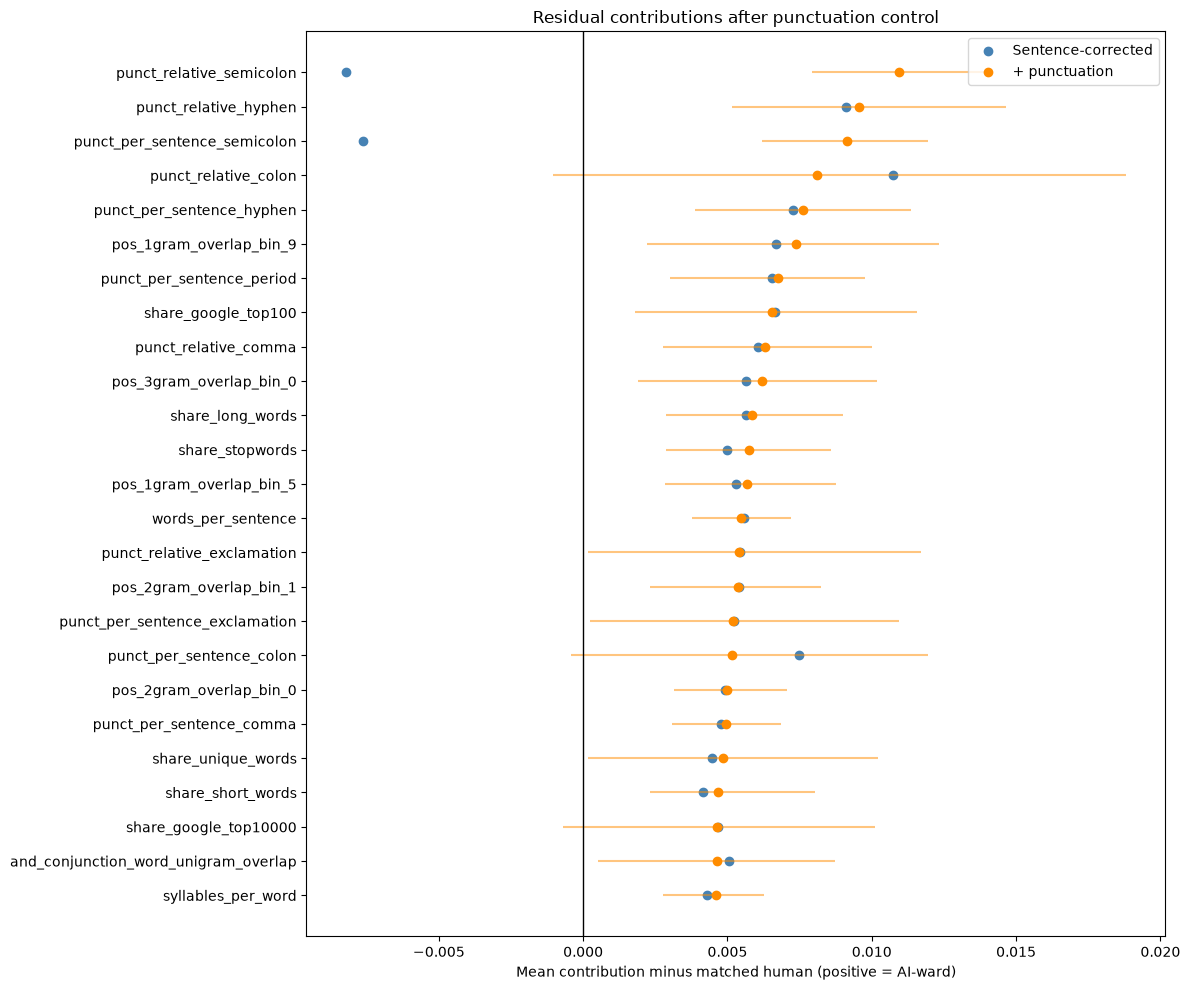

Saved: ../results/causal/C02n_punctuation_after_sentences
Periods and sentence counts preserved; variance was not targeted.
Hyphen templates currently cover spaced clause separators, not compound words.


In [11]:
# Punctuation on top of sentence correction:
# nontrivial marks first, then commas. No period edits.
from collections import Counter

PUNCT_OUT = ROOT / "results/causal/C02n_punctuation_after_sentences"
PUNCT_OUT.mkdir(parents=True, exist_ok=True)

PMARKS = {
    "semicolon": ";", "colon": ":", "hyphen": "-",
    "en_dash": "–", "em_dash": "—", "comma": ","
}
PSTAGES = [
    ["semicolon", "colon", "hyphen", "en_dash", "em_dash"],
    ["comma"]
]
MEANS = ["wps_mean", "cps_mean"]

# Freeze these references from C02l; do not rematch after editing.
sentence_results = list(results)


def punct_values(text, stats=None):
    if stats is None:
        stats, _ = measure(nlp(text))
    return {
        (mark, denominator): text.count(symbol) / max(1, stats[count_key])
        for mark, symbol in PMARKS.items()
        for denominator, count_key in [("relative", "C"), ("per_sentence", "S")]
    }


def punct_candidates(text, stage):
    """Local templates; all candidates are reparsed before acceptance."""
    doc = nlp(text)
    edits = []

    def emit(start, end, replacement, rule):
        old = text[start:end]
        if old == replacement:
            return
        # Never edit a span containing a period, or introduce a period.
        if "." in old or "." in replacement:
            return
        edits.append(dict(
            start=start, end=end, replacement=replacement, rule=rule
        ))

    for sentence in doc.sents:
        segment = sentence.text
        offset = sentence.start_char

        if stage == 0:
            # Increment semicolons at coordinated independent clauses.
            for match in re.finditer(r",?\s+and\s+", segment, re.I):
                if independent(segment[:match.start()]) and independent(
                    segment[match.end():]
                ):
                    emit(
                        offset + match.start(), offset + match.end(),
                        "; ", "and_to_semicolon"
                    )

            # Explicit explanation -> colon or dash.
            for match in re.finditer(
                r",?\s+(?:that is(?: to say)?|in other words),?\s+",
                segment, re.I
            ):
                if independent(segment[:match.start()]) and independent(
                    segment[match.end():]
                ):
                    for replacement in [": ", " — ", " – ", " - "]:
                        emit(
                            offset + match.start(), offset + match.end(),
                            replacement, "explanation_to_separator"
                        )

            # Decrement clause-level separators.
            for match in re.finditer(
                r"\s*([;:—–]|(?<=\s)-(?=\s))\s*", segment
            ):
                symbol = match.group(1)
                if symbol in "—–-" and segment.count(symbol) != 1:
                    continue  # Paired dashes require a separate template.

                left = segment[:match.start()]
                right = segment[match.end():]
                if not (independent(left) and independent(right)):
                    continue

                replacement = ", that is, " if symbol == ":" else ", and "
                emit(
                    offset + match.start(), offset + match.end(),
                    replacement, "separator_to_connective"
                )

        else:
            # Optional coordination comma; preserve the conjunction.
            for match in re.finditer(
                r"(,?)\s+(and|but|yet|so|or|nor)\s+", segment, re.I
            ):
                if independent(segment[:match.start()]) and independent(
                    segment[match.end():]
                ):
                    conjunction = match.group(2)
                    replacement = (
                        f" {conjunction} " if match.group(1)
                        else f", {conjunction} "
                    )
                    emit(
                        offset + match.start(), offset + match.end(),
                        replacement, "coordination_comma_toggle"
                    )

            # Sentence-initial transition comma.
            match = re.match(
                r"(\s*)(However|Therefore|Moreover|Nevertheless|Meanwhile|"
                r"Furthermore)(,?)\s+", segment, re.I
            )
            if match:
                replacement = (
                    match.group(1) + match.group(2)
                    + (" " if match.group(3) else ", ")
                )
                emit(
                    offset + match.start(), offset + match.end(),
                    replacement, "transition_comma_toggle"
                )

    unique_edits = {
        (e["start"], e["end"], e["replacement"]): e for e in edits
    }
    return [unique_edits[key] for key in sorted(unique_edits)]


def outside(value, low, high):
    return max(low - value, 0.0, value - high)


# Build human bounds for both denominators using the SAME reference texts.
punct_cases = []
for case, state in sentence_results:
    assert state["status"] in {"in_band", "no_eligible_improving_candidate"}
    start_text = state["text"]
    initial_stats, _ = measure(nlp(start_text))

    reference_values = [
        punct_values(normalize(text_map[source_id]))
        for source_id in case["reference_ids"]
    ]
    bounds_p = {}
    for key in reference_values[0]:
        values = np.array([row[key] for row in reference_values])
        low, center, high = np.quantile(values, [.2, .4, .6])
        bounds_p[key] = dict(low=float(low), center=float(center), high=float(high))

    # Fixed scales prevent apparent progress merely from changing denominators.
    scales = {
        key: max(
            b["high"] - b["low"],
            1 / max(1, initial_stats["C" if key[1] == "relative" else "S"])
        )
        for key, b in bounds_p.items()
    }
    punct_cases.append(dict(
        case_id=case["case_id"], domain=case["domain"],
        text=start_text, initial_stats=initial_stats,
        reference_ids=case["reference_ids"],
        mean_bounds={m: case["bounds"][m] for m in MEANS},
        punctuation_bounds=bounds_p, scales=scales
    ))


def band_loss(values, case, marks):
    return sum(
        outside(values[key], bound["low"], bound["high"]) / case["scales"][key]
        for key, bound in case["punctuation_bounds"].items()
        if key[0] in marks
    )


punct_results, edit_rows, outcome_rows, stop_rows = [], [], [], []

for case in punct_cases:
    text = case["text"]
    initial = case["initial_stats"]
    initial_periods = text.count(".")
    initial_natural = (text.count("?"), text.count("!"))
    initial_mean_distance = {
        m: outside(initial[m], **{
            k: case["mean_bounds"][m][k] for k in ["low", "high"]
        })
        for m in MEANS
    }
    audit = []
    seen = {text}

    for stage, marks in enumerate(PSTAGES):
        while True:
            stats, _ = measure(nlp(text))
            values = punct_values(text, stats)
            loss = band_loss(values, case, marks)

            if loss <= 1e-12:
                reason, counts = "in_band", Counter()
                break

            counts, options = Counter(), []
            for edit in punct_candidates(text, stage):
                counts["proposed"] += 1
                candidate = (
                    text[:edit["start"]] + edit["replacement"]
                    + text[edit["end"]:]
                )
                if candidate in seen:
                    counts["visited"] += 1
                    continue

                after, _ = measure(nlp(candidate))
                if candidate.count(".") != initial_periods:
                    counts["period_change"] += 1
                    continue
                if after["S"] != initial["S"]:
                    counts["sentence_count_change"] += 1
                    continue
                if (candidate.count("?"), candidate.count("!")) != initial_natural:
                    counts["natural_punctuation_change"] += 1
                    continue

                # Comma stage must preserve every nontrivial mark's count.
                if stage == 1 and any(
                    candidate.count(PMARKS[m]) != text.count(PMARKS[m])
                    for m in PSTAGES[0]
                ):
                    counts["nontrivial_count_change"] += 1
                    continue

                # Preserve achieved mean control relative to this stage's input.
                if any(
                    outside(
                        after[m],
                        case["mean_bounds"][m]["low"],
                        case["mean_bounds"][m]["high"]
                    ) > initial_mean_distance[m] + 1e-12
                    for m in MEANS
                ):
                    counts["mean_control_regression"] += 1
                    continue

                new_values = punct_values(candidate, after)
                new_loss = band_loss(new_values, case, marks)
                if new_loss >= loss - 1e-12:
                    counts["no_joint_punctuation_improvement"] += 1
                    continue

                # Require improvement in a mark actually edited; avoid
                # "fixing" punctuation solely by expanding its denominator.
                targeted_q = []
                for mark in marks:
                    if candidate.count(PMARKS[mark]) == text.count(PMARKS[mark]):
                        continue
                    old_mark_loss = band_loss(values, case, [mark])
                    new_mark_loss = band_loss(new_values, case, [mark])
                    if old_mark_loss > new_mark_loss + 1e-12:
                        targeted_q.append(old_mark_loss)

                if not targeted_q:
                    counts["no_edited_mark_improvement"] += 1
                    continue

                # Do not worsen the completed nontrivial stage through
                # denominator drift when editing commas.
                if stage == 1 and (
                    band_loss(new_values, case, PSTAGES[0])
                    > band_loss(values, case, PSTAGES[0]) + 1e-12
                ):
                    counts["nontrivial_rate_regression"] += 1
                    continue

                threshold = bar(max(targeted_q))
                scored = score_edit(text, edit)
                if scored is None:
                    counts["likelihood_unscorable"] += 1
                    continue
                if scored["mutability"] < threshold:
                    counts["below_threshold"] += 1
                    continue

                options.append((
                    scored["mutability"], loss - new_loss,
                    candidate, edit, after, threshold
                ))

            if not options:
                reason = "no_eligible_improving_candidate"
                break

            options.sort(key=lambda row: (-row[0], -row[1], row[2]))
            mutability, gain, candidate, edit, after, threshold = options[0]
            audit.append(dict(
                case_id=case["case_id"], stage=stage,
                step=len(audit) + 1, **edit,
                before_text=text, after_text=candidate,
                objective_before=loss, objective_after=loss - gain,
                mutability=mutability, threshold=threshold
            ))
            text = candidate
            seen.add(text)
            print(
                case["case_id"], "|", "nontrivial" if stage == 0 else "comma",
                "| edits", len(audit), "| loss", round(loss - gain, 4),
                flush=True
            )

        stop_rows.append(dict(
            case_id=case["case_id"], stage=stage, status=reason, **counts
        ))

    final, _ = measure(nlp(text))
    assert text.count(".") == initial_periods
    assert final["S"] == initial["S"]

    punct_results.append((case, text))
    edit_rows.extend(audit)
    for condition, t in [
        ("sentence_corrected", case["text"]),
        ("sentence_plus_punctuation", text)
    ]:
        measured, _ = measure(nlp(t))
        pv = punct_values(t, measured)
        for (mark, denominator), value in pv.items():
            bound = case["punctuation_bounds"][(mark, denominator)]
            outcome_rows.append(dict(
                case_id=case["case_id"], condition=condition,
                mark=mark, denominator=denominator, value=value,
                distance=outside(value, bound["low"], bound["high"]),
                in_band=bound["low"] <= value <= bound["high"],
                **bound
            ))

pairs = pd.DataFrame([
    dict(
        case_id=c["case_id"], domain=c["domain"],
        before=c["text"], after=t,
        **{"before_" + m: c["initial_stats"][m]
           for m in MEANS + ["share_unique_words", "cpw_mean", "cpw_var"]},
        **{"after_" + m: measure(nlp(t))[0][m]
           for m in MEANS + ["share_unique_words", "cpw_mean", "cpw_var"]}
    )
    for c, t in punct_results
])
pairs.to_csv(PUNCT_OUT / "text_pairs.csv", index=False)
pd.DataFrame(edit_rows).to_csv(PUNCT_OUT / "accepted_edits.csv", index=False)
pd.DataFrame(stop_rows).to_csv(PUNCT_OUT / "stopping_checks.csv", index=False)
punct_outcomes = pd.DataFrame(outcome_rows)
punct_outcomes.to_csv(PUNCT_OUT / "punctuation_outcomes.csv", index=False)
if not (PUNCT_OUT / "manual_review.csv").exists():
    pairs.assign(meaning_preserved="", grammar_acceptable="", notes="").to_csv(
        PUNCT_OUT / "manual_review.csv", index=False
    )

display(pd.DataFrame(stop_rows).fillna(0))
display(punct_outcomes.groupby(
    ["mark", "denominator", "condition"]
).agg(mean=("value", "mean"), in_band=("in_band", "mean"),
      distance=("distance", "mean")))

# Frozen-detector residual ranking: same cases, same human references.
records, vectors = [], []
for case, text in punct_results:
    for condition, t in [
        ("sentence_corrected", case["text"]),
        ("sentence_plus_punctuation", text)
    ]:
        records.append(dict(case_id=case["case_id"], condition=condition))
        vectors.append(extract_fz118(normalize(t)))

pindex = pd.MultiIndex.from_frame(pd.DataFrame(records))
pframe = pd.DataFrame(vectors, index=pindex, columns=FEATURE_NAMES)
pcontrib = pd.DataFrame(
    contributions(pframe[model_features]),
    index=pindex, columns=model_features
)
pframe.to_csv(PUNCT_OUT / "all_feature_values.csv")
pcontrib.to_csv(PUNCT_OUT / "tree_contributions.csv")

pscores = pd.Series(
    detector.predict_proba(pframe[model_features])[:, 1],
    index=pindex
).unstack("condition")
pscores["change"] = (
    pscores.sentence_plus_punctuation - pscores.sentence_corrected
)
pscores.to_csv(PUNCT_OUT / "detector_scores.csv")
display(pscores)

pgaps = {}
for condition in ["sentence_corrected", "sentence_plus_punctuation"]:
    pgaps[condition] = pd.DataFrame([
        pcontrib.loc[(c["case_id"], condition)].values
        - human_contrib.loc[c["reference_ids"]].mean().values
        for c, t in punct_results
    ], columns=model_features)

rng = np.random.default_rng(2026)
a = pgaps["sentence_plus_punctuation"].to_numpy()
boot = np.array([
    a[rng.integers(0, len(a), len(a))].mean(axis=0)
    for _ in range(2000)
])
pranking = pd.DataFrame({
    "before_gap": pgaps["sentence_corrected"].mean(),
    "corrected_gap": pgaps["sentence_plus_punctuation"].mean(),
    "ci_low": np.quantile(boot, .025, axis=0),
    "ci_high": np.quantile(boot, .975, axis=0)
})
pranking["before_rank"] = pranking.before_gap.rank(
    ascending=False, method="min"
).astype(int)
pranking = pranking.sort_values("corrected_gap", ascending=False)
pranking["corrected_rank"] = np.arange(1, len(pranking) + 1)
pranking.to_csv(PUNCT_OUT / "residual_feature_ranking.csv")
display(pranking.head(25))

top = pranking.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 10))
y = np.arange(len(top))
ax.hlines(y, top.ci_low, top.ci_high, color="darkorange", alpha=.5)
ax.scatter(top.before_gap, y, label="Sentence-corrected", color="steelblue")
ax.scatter(top.corrected_gap, y, label="+ punctuation", color="darkorange")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y, top.index)
ax.set_xlabel("Mean contribution minus matched human (positive = AI-ward)")
ax.set_title("Residual contributions after punctuation control")
ax.legend()
fig.tight_layout()
fig.savefig(PUNCT_OUT / "residual_ranking.png", dpi=180, bbox_inches="tight")
plt.show()

# Inspect accepted edits using the wrapped diff helper from V2.
if "show_local_diff" in globals():
    for edit in edit_rows:
        show_local_diff(
            edit["before_text"], edit["after_text"],
            f"{edit['case_id']} | {edit['rule']} | edit {edit['step']}"
        )

print("Saved:", PUNCT_OUT)
print("Periods and sentence counts preserved; variance was not targeted.")
print("Hyphen templates currently cover spaced clause separators, not compound words.")

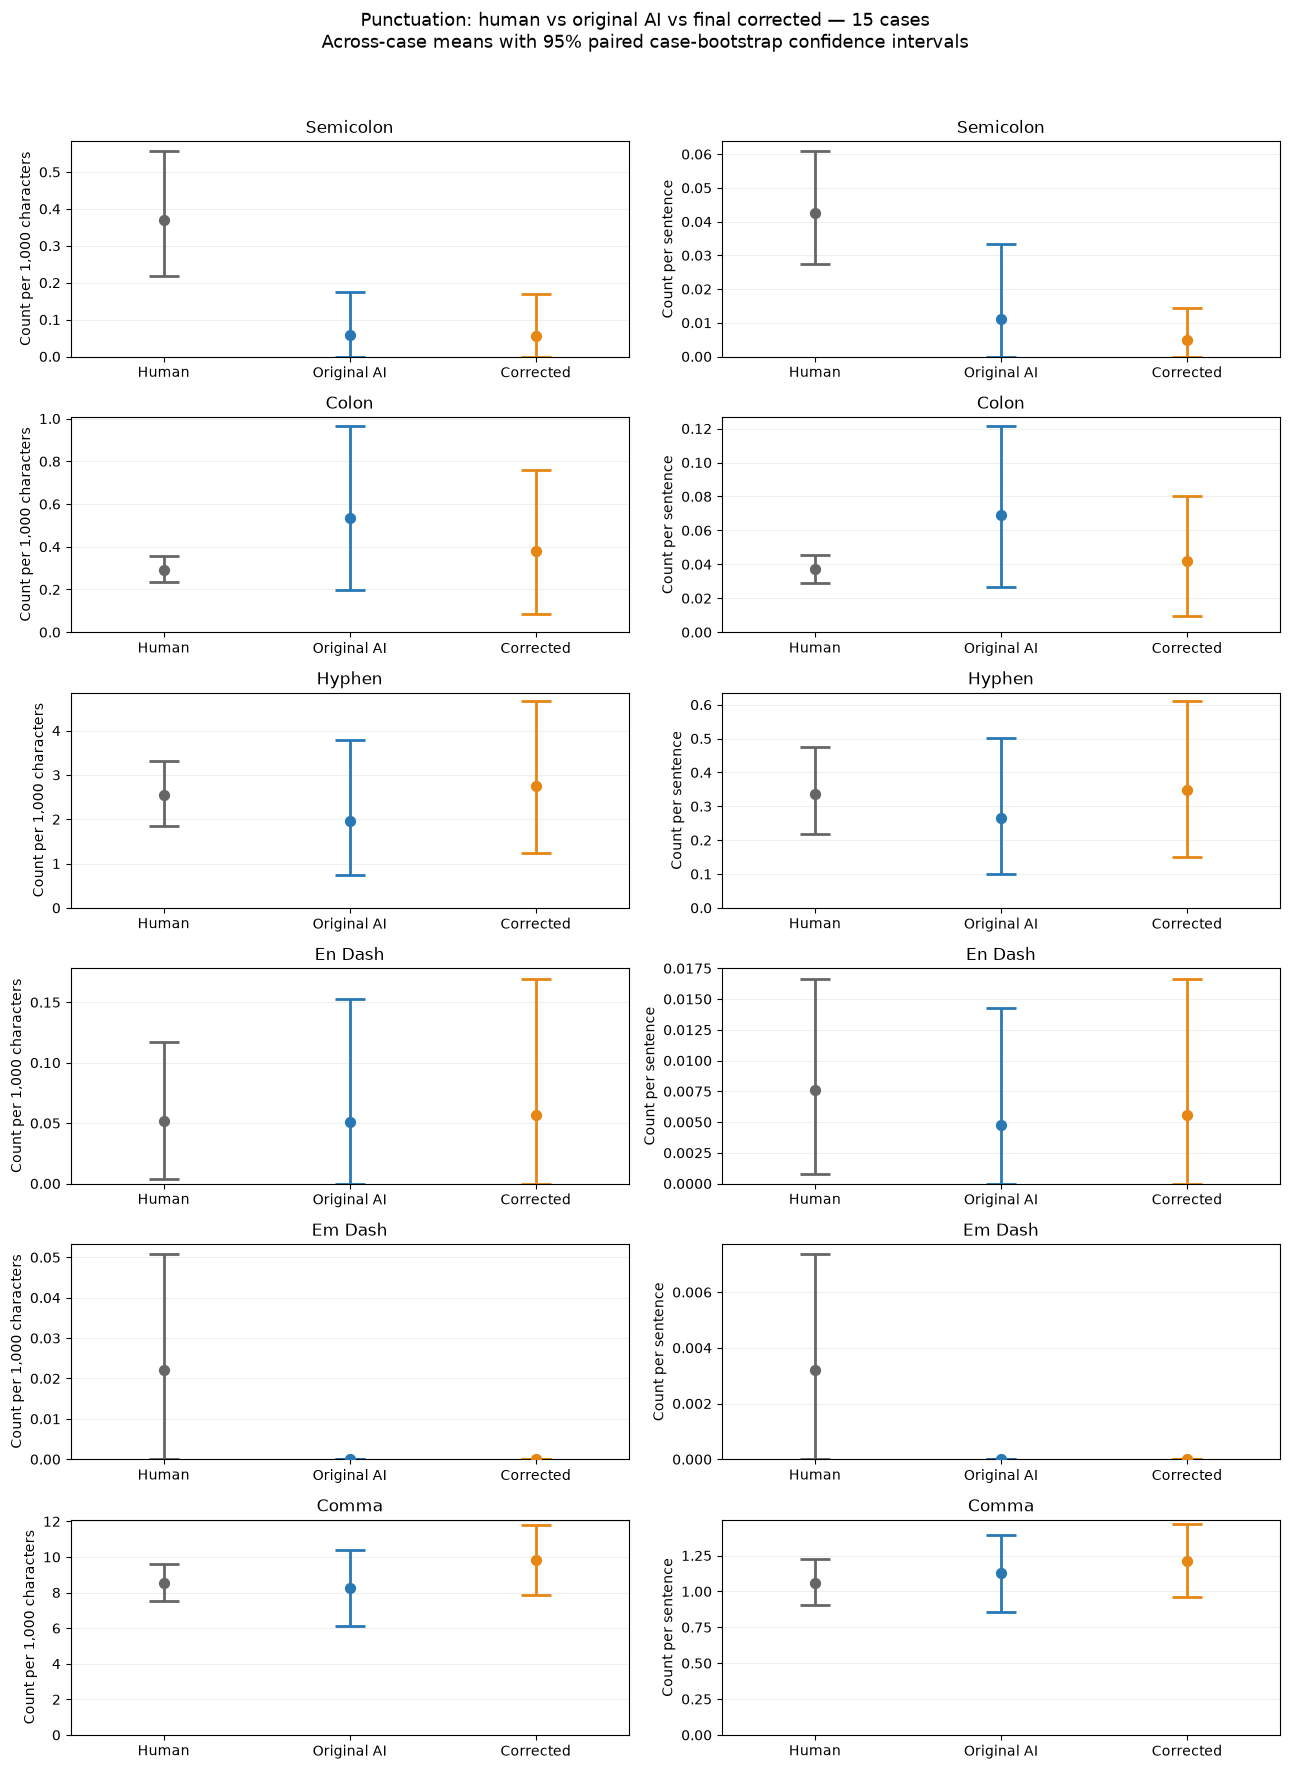

Mean rates and CIs — relative rates below are per character:


,mark,denominator,condition,mean,ci_low,ci_high,n_cases
0,semicolon,relative,Human,0.000371,0.000219,0.000556,15
1,semicolon,relative,Original AI,0.000058,0.000000,0.000174,15
2,semicolon,relative,Corrected,0.000056,0.000000,0.000169,15
3,semicolon,per_sentence,Human,0.042693,0.027370,0.060799,15
4,semicolon,per_sentence,Original AI,0.011111,0.000000,0.033333,15
5,semicolon,per_sentence,Corrected,0.004762,0.000000,0.014286,15
6,colon,relative,Human,0.000293,0.000233,0.000356,15
7,colon,relative,Original AI,0.000536,0.000195,0.000964,15
8,colon,relative,Corrected,0.000381,0.000086,0.000757,15
9,colon,per_sentence,Human,0.037039,0.028860,0.045439,15


Paired differences:


,mark,denominator,comparison,mean_difference,ci_low,ci_high
0,semicolon,relative,Original AI minus Human,-0.000313,-0.000534,-0.000085
1,semicolon,relative,Corrected minus Human,-0.000314,-0.000428,-0.000214
2,semicolon,relative,Corrected minus Original AI,-0.000002,-0.000174,0.000169
3,semicolon,per_sentence,Original AI minus Human,-0.031582,-0.057588,0.001020
4,semicolon,per_sentence,Corrected minus Human,-0.037931,-0.054064,-0.024972
5,semicolon,per_sentence,Corrected minus Original AI,-0.006349,-0.033333,0.014286
6,colon,relative,Original AI minus Human,0.000243,-0.000084,0.000634
7,colon,relative,Corrected minus Human,0.000088,-0.000202,0.000430
8,colon,relative,Corrected minus Original AI,-0.000155,-0.000319,-0.000012
9,colon,per_sentence,Original AI minus Human,0.032180,-0.014479,0.086713


Fraction of documents with ZERO occurrences:


,Human,Original AI,Corrected
mark,,,
semicolon,0.766,0.933,0.933
colon,0.758,0.533,0.733
hyphen,0.196,0.333,0.133
en_dash,0.956,0.933,0.933
em_dash,0.982,1.000,1.000
comma,0.007,0.000,0.000


Corrected includes unique-word regeneration, sentence correction, and punctuation editing. Original AI is the source text.
These are CIs for mean rates, not human acceptance bands. Human-reference pools are fixed; overlapping references are not independent new human documents.


In [12]:
# Human vs original AI vs final punctuation-corrected text.
# Rows: punctuation marks. Columns: per-character and per-sentence rates.
# CIs describe across-case means, conditional on fixed human references.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

conditions = ["Human", "Original AI", "Corrected"]
marks = list(PMARKS)
denominators = ["relative", "per_sentence"]
BOOTSTRAPS = 5000
rng = np.random.default_rng(2026)

manifest_index = manifest.set_index("case_id")
assert manifest_index.index.is_unique

reference_cache = {}

def get_reference_punctuation(source_id):
    if source_id not in reference_cache:
        text = normalize(text_map[source_id])
        stats, _ = measure(nlp(text))
        reference_cache[source_id] = (
            punct_values(text, stats),
            {m: text.count(symbol) for m, symbol in PMARKS.items()}
        )
    return reference_cache[source_id]

rows = []
for case, corrected_text in punct_results:
    case_id = case["case_id"]
    original_id = manifest_index.loc[case_id, "source_id"]
    original_rates, original_counts = get_reference_punctuation(original_id)

    corrected_text = normalize(corrected_text)
    corrected_rates = punct_values(corrected_text)
    corrected_counts = {
        m: corrected_text.count(symbol)
        for m, symbol in PMARKS.items()
    }
    human_refs = [
        get_reference_punctuation(source_id)
        for source_id in case["reference_ids"]
    ]
    assert human_refs

    for mark in marks:
        for denominator in denominators:
            key = (mark, denominator)
            rows.append({
                "case_id": case_id,
                "domain": case["domain"],
                "mark": mark,
                "denominator": denominator,
                "Human": np.mean([rates[key] for rates, counts in human_refs]),
                "Original AI": original_rates[key],
                "Corrected": corrected_rates[key],
                "human_zero_fraction": np.mean([
                    counts[mark] == 0 for rates, counts in human_refs
                ]),
                "original_zero": float(original_counts[mark] == 0),
                "corrected_zero": float(corrected_counts[mark] == 0),
            })

punct_ci_cases = pd.DataFrame(rows)
case_ids = sorted(punct_ci_cases.case_id.unique())
assert len(case_ids) >= 2

# Identical case resamples for every condition and metric.
draws = rng.integers(
    0, len(case_ids), size=(BOOTSTRAPS, len(case_ids))
)
summary_rows, difference_rows = [], []

for mark in marks:
    for denominator in denominators:
        block = (
            punct_ci_cases.loc[
                (punct_ci_cases.mark == mark)
                & (punct_ci_cases.denominator == denominator)
            ]
            .set_index("case_id")
            .loc[case_ids, conditions]
        )
        values = block.to_numpy(dtype=float)
        assert np.isfinite(values).all()
        boot = values[draws].mean(axis=1)

        for j, condition in enumerate(conditions):
            low, high = np.quantile(boot[:, j], [.025, .975])
            summary_rows.append({
                "mark": mark,
                "denominator": denominator,
                "condition": condition,
                "mean": values[:, j].mean(),
                "ci_low": low,
                "ci_high": high,
                "n_cases": len(case_ids),
            })

        for label, left, right in [
            ("Original AI minus Human", 1, 0),
            ("Corrected minus Human", 2, 0),
            ("Corrected minus Original AI", 2, 1),
        ]:
            delta = boot[:, left] - boot[:, right]
            low, high = np.quantile(delta, [.025, .975])
            difference_rows.append({
                "mark": mark,
                "denominator": denominator,
                "comparison": label,
                "mean_difference": (
                    values[:, left] - values[:, right]
                ).mean(),
                "ci_low": low,
                "ci_high": high,
            })

punct_ci_summary = pd.DataFrame(summary_rows)
punct_ci_differences = pd.DataFrame(difference_rows)

colors = {
    "Human": "#666666",
    "Original AI": "#2878B5",
    "Corrected": "#E68613",
}

fig, axes = plt.subplots(
    len(marks), 2, figsize=(13, 3 * len(marks)), squeeze=False
)

for row_index, mark in enumerate(marks):
    for column_index, denominator in enumerate(denominators):
        ax = axes[row_index, column_index]
        panel = (
            punct_ci_summary.loc[
                (punct_ci_summary.mark == mark)
                & (punct_ci_summary.denominator == denominator)
            ]
            .set_index("condition")
            .loc[conditions]
        )

        # Display relative counts per 1,000 characters for readability.
        multiplier = 1000 if denominator == "relative" else 1

        for x, condition in enumerate(conditions):
            r = panel.loc[condition]
            low, mean, high = (
                multiplier * r.ci_low,
                multiplier * r["mean"],
                multiplier * r.ci_high,
            )
            ax.vlines(x, low, high, color=colors[condition], lw=2)
            ax.hlines(
                [low, high], x - .08, x + .08,
                color=colors[condition], lw=2
            )
            ax.scatter(
                x, mean, color=colors[condition], s=50, zorder=3
            )

        ax.set_xticks(range(3), conditions)
        ax.set_xlim(-.5, 2.5)
        ax.set_ylim(bottom=0)
        ax.set_title(mark.replace("_", " ").title())
        ax.set_ylabel(
            "Count per 1,000 characters"
            if denominator == "relative"
            else "Count per sentence"
        )
        ax.grid(axis="y", alpha=.2)

fig.suptitle(
    f"Punctuation: human vs original AI vs final corrected — {len(case_ids)} cases\n"
    "Across-case means with 95% paired case-bootstrap confidence intervals",
    fontsize=13
)
fig.tight_layout(rect=[0, 0, 1, .96])
fig.savefig(
    PUNCT_OUT / "human_original_corrected_punctuation_CIs.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

# Each case contributes equally, including its matched human zero-use fraction.
zero_use = (
    punct_ci_cases.loc[punct_ci_cases.denominator == "relative"]
    .groupby("mark")[
        ["human_zero_fraction", "original_zero", "corrected_zero"]
    ]
    .mean()
    .rename(columns={
        "human_zero_fraction": "Human",
        "original_zero": "Original AI",
        "corrected_zero": "Corrected",
    })
    .reindex(marks)
)

with pd.option_context("display.max_rows", None):
    print("Mean rates and CIs — relative rates below are per character:")
    display(punct_ci_summary.round(6))

    print("Paired differences:")
    display(punct_ci_differences.round(6))

    print("Fraction of documents with ZERO occurrences:")
    display(zero_use.round(3))

punct_ci_cases.to_csv(
    PUNCT_OUT / "punctuation_CI_case_values.csv", index=False
)
punct_ci_summary.to_csv(
    PUNCT_OUT / "punctuation_CI_summary.csv", index=False
)
punct_ci_differences.to_csv(
    PUNCT_OUT / "punctuation_CI_differences.csv", index=False
)
zero_use.to_csv(PUNCT_OUT / "punctuation_zero_use.csv")

print(
    "Corrected includes unique-word regeneration, sentence correction, "
    "and punctuation editing. Original AI is the source text."
)
print(
    "These are CIs for mean rates, not human acceptance bands. "
    "Human-reference pools are fixed; overlapping references are not "
    "independent new human documents."
)

In [13]:
# Audit semicolon reference bands against actual counts and saved bounds.
audit_rows = []

for case, corrected_text in punct_results:
    refs = []
    for source_id in case["reference_ids"]:
        text = normalize(text_map[source_id])
        stats, _ = measure(nlp(text))
        count = text.count(";")
        refs.append({
            "count": count,
            "relative": count / max(1, stats["C"]),
            "per_sentence": count / max(1, stats["S"]),
        })

    ref = pd.DataFrame(refs)
    text = normalize(corrected_text)
    stats, _ = measure(nlp(text))
    count = text.count(";")

    for denominator, divisor in [
        ("relative", stats["C"]),
        ("per_sentence", stats["S"]),
    ]:
        q20, q40, q60 = ref[denominator].quantile([.2, .4, .6])
        value = count / max(1, divisor)
        saved = case["punctuation_bounds"][("semicolon", denominator)]
        scale = 1000 if denominator == "relative" else 1

        audit_rows.append({
            "case_id": case["case_id"],
            "units": (
                "per 1000 chars" if denominator == "relative"
                else "per sentence"
            ),
            "human_n": len(ref),
            "human_zero_fraction": (ref["count"] == 0).mean(),
            "human_mean": ref[denominator].mean() * scale,
            "q20": q20 * scale,
            "q40": q40 * scale,
            "q60": q60 * scale,
            "corrected_count": count,
            "corrected_rate": value * scale,
            "recomputed_in_band": q20 <= value <= q60,
            "zero_width_zero_band": q20 == 0 and q60 == 0,
            "saved_bounds_match": np.allclose(
                [q20, q40, q60],
                [saved["low"], saved["center"], saved["high"]],
                rtol=1e-10, atol=1e-12,
            ),
        })

semicolon_audit = pd.DataFrame(audit_rows)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(semicolon_audit.round(6))

print(
    "Saved bounds match recomputed bounds:",
    bool(semicolon_audit.saved_bounds_match.all())
)
print(
    "Cases with a [0, 0] relative-frequency band:",
    int(semicolon_audit.loc[
        semicolon_audit.units == "per 1000 chars",
        "zero_width_zero_band"
    ].sum()),
    "/", len(punct_results)
)

,case_id,units,human_n,human_zero_fraction,human_mean,q20,q40,q60,corrected_count,corrected_rate,recomputed_in_band,zero_width_zero_band,saved_bounds_match
0,raid_residual_03,per 1000 chars,30,0.800000,0.161486,0.0,0.000000,0.000000,0,0.000000,True,True,True
1,raid_residual_03,per sentence,30,0.800000,0.020916,0.0,0.000000,0.000000,0,0.000000,True,True,True
2,raid_residual_05,per 1000 chars,30,0.700000,0.371929,0.0,0.000000,0.000000,0,0.000000,True,True,True
3,raid_residual_05,per sentence,30,0.700000,0.035435,0.0,0.000000,0.000000,0,0.000000,True,True,True
4,raid_residual_09,per 1000 chars,30,0.966667,0.086505,0.0,0.000000,0.000000,0,0.000000,True,True,True
5,raid_residual_09,per sentence,30,0.966667,0.016667,0.0,0.000000,0.000000,0,0.000000,True,True,True
6,raid_residual_10,per 1000 chars,30,0.666667,0.324865,0.0,0.000000,0.000000,0,0.000000,True,True,True
7,raid_residual_10,per sentence,30,0.666667,0.040955,0.0,0.000000,0.000000,0,0.000000,True,True,True
8,raid_residual_14,per 1000 chars,20,0.900000,0.129134,0.0,0.000000,0.000000,0,0.000000,True,True,True
9,raid_residual_14,per sentence,20,0.900000,0.015000,0.0,0.000000,0.000000,0,0.000000,True,True,True


Saved bounds match recomputed bounds: True
Cases with a [0, 0] relative-frequency band: 13 / 15


In [14]:
# Human-mean target rounding + stronger punctuation enforcement.
# Requires the previous punctuation cell's helpers and punct_cases.
from collections import Counter
import hashlib
import json
import numpy as np
import pandas as pd

ROUND_OUT = ROOT / "results/causal/C02o_human_rounding"
ROUND_OUT.mkdir(parents=True, exist_ok=True)

ARTIFICIAL_SD_SCALE = 0.5
BUMP_P_MIN = 0.10
BUMP_ALPHA = 1.0
REFERENCE_BOOTSTRAPS = 3000
ROUND_SEED = 2026
MIN_GENRE_DOCUMENTS = 15

assert 0 < ARTIFICIAL_SD_SCALE < 1
assert 0 < BUMP_P_MIN < 1
assert BUMP_ALPHA > 0

# Always start from the sentence-corrected text stored in punct_cases.
round_cases = list(punct_cases)
assert round_cases and all(
    str(c["domain"]).strip().lower() != "poetry" for c in round_cases
)

def stable_rng(*parts):
    payload = json.dumps([ROUND_SEED, *parts], sort_keys=True).encode()
    seed = int.from_bytes(hashlib.sha256(payload).digest()[:8], "big")
    return np.random.default_rng(seed)

# Training-only genre references. No duplicate documents from overlapping pools.
training_features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
training_meta = training_features.loc[
    (training_features.dataset == "raid")
    & (training_features.split == "train"),
    ["source_id", "domain", "label"]
].copy()
assert training_meta.source_id.is_unique
training_meta["domain"] = (
    training_meta.domain.astype(str).str.strip().str.lower()
)
needed_genres = {
    str(c["domain"]).strip().lower() for c in round_cases
}
training_meta = training_meta.loc[
    training_meta.domain.isin(needed_genres)
].sort_values("source_id")
assert training_meta.source_id.isin(text_map).all()

reference_rows = []
for row in training_meta.to_dict("records"):
    text = normalize(text_map[row["source_id"]])
    values = punct_values(text)
    for (mark, denominator), value in values.items():
        reference_rows.append({
            **row, "mark": mark,
            "denominator": denominator, "value": value
        })

training_rates = pd.DataFrame(reference_rows)
genre_stats = {}

for (genre, mark, denominator), group in training_rates.groupby(
    ["domain", "mark", "denominator"], sort=True
):
    human_values = group.loc[group.label == 0, "value"].to_numpy(float)
    ai_values = group.loc[group.label == 1, "value"].to_numpy(float)

    supported = (
        len(human_values) >= MIN_GENRE_DOCUMENTS
        and len(ai_values) >= MIN_GENRE_DOCUMENTS
    )
    human_mean = (
        float(human_values.mean()) if len(human_values) else np.nan
    )
    ai_mean = float(ai_values.mean()) if len(ai_values) else np.nan

    if len(human_values) >= 2:
        rng = stable_rng("bootstrap", genre, mark, denominator)
        boot_means = np.array([
            human_values[
                rng.integers(0, len(human_values), len(human_values))
            ].mean()
            for _ in range(REFERENCE_BOOTSTRAPS)
        ])
        bootstrap_sd = float(boot_means.std(ddof=1))
    else:
        bootstrap_sd = np.nan

    artificial_sd = ARTIFICIAL_SD_SCALE * bootstrap_sd
    genre_stats[(genre, mark, denominator)] = dict(
        human_n=len(human_values), ai_n=len(ai_values),
        human_mean=human_mean, ai_mean=ai_mean,
        bootstrap_sd=bootstrap_sd,
        artificial_sd=artificial_sd,
        artificial_low=max(0.0, human_mean - artificial_sd),
        artificial_high=human_mean + artificial_sd,
        ai_direction=(
            int(np.sign(ai_mean - human_mean)) if supported else 0
        ),
        supported=supported
    )

genre_table = pd.DataFrame([
    dict(domain=g, mark=m, denominator=d, **stats)
    for (g, m, d), stats in genre_stats.items()
])
genre_table.to_csv(ROUND_OUT / "genre_mean_reference.csv", index=False)


# Draw once per case and mark. One draw jointly serves both denominators.
round_targets = {}
target_audit = []

for case in round_cases:
    genre = str(case["domain"]).strip().lower()
    initial, _ = measure(nlp(case["text"]))

    for mark in PMARKS:
        tests = []
        for denominator in ["relative", "per_sentence"]:
            reference = genre_stats[(genre, mark, denominator)]
            local = case["punctuation_bounds"][(mark, denominator)]
            direction = reference["ai_direction"]

            triggered = (
                reference["supported"]
                and (
                    (direction > 0 and
                     local["low"] > reference["artificial_high"])
                    or
                    (direction < 0 and
                     local["high"] < reference["artificial_low"])
                )
            )

            distance = max(
                reference["artificial_low"] - local["high"],
                local["low"] - reference["artificial_high"],
                0.0
            )
            # Use unscaled uncertainty for probability decay.
            denominator_scale = max(
                reference["bootstrap_sd"],
                abs(reference["human_mean"]) * 1e-6,
                1e-12
            )
            standardized_distance = distance / denominator_scale
            probability = (
                BUMP_P_MIN
                + (1 - BUMP_P_MIN)
                / (1 + BUMP_ALPHA * standardized_distance)
                if triggered else 0.0
            )
            tests.append(dict(
                denominator=denominator,
                triggered=triggered,
                probability=probability,
                distance=distance,
                standardized_distance=standardized_distance,
                **reference
            ))

        # A displacement in either metric may trigger the mark-level bump.
        chosen_test = max(tests, key=lambda x: x["probability"])
        probability = chosen_test["probability"]
        rng = stable_rng("target", case["case_id"], mark)
        draw = float(rng.random())
        bumped = probability > 0 and draw < probability

        target_count = None
        expected_count = np.nan
        if bumped:
            # Fixed sentence count provides the stable integer target.
            ref_sentence = genre_stats[(genre, mark, "per_sentence")]
            expected_count = ref_sentence["human_mean"] * initial["S"]
            lower = int(np.floor(expected_count))
            target_count = lower + int(
                rng.random() < expected_count - lower
            )

        round_targets[(case["case_id"], mark)] = target_count

        for test in tests:
            divisor = (
                initial["C"] if test["denominator"] == "relative"
                else initial["S"]
            )
            local = case["punctuation_bounds"][
                (mark, test["denominator"])
            ]
            target_audit.append(dict(
                case_id=case["case_id"], domain=genre, mark=mark,
                **test,
                local_low=local["low"], local_high=local["high"],
                mark_bump_probability=probability,
                bump_draw=draw, bumped=bumped,
                expected_count=expected_count,
                target_count=target_count,
                implied_initial_rate=(
                    target_count / max(1, divisor)
                    if bumped else np.nan
                )
            ))

target_table = pd.DataFrame(target_audit)
target_table.to_csv(ROUND_OUT / "target_rounding_audit.csv", index=False)

display(target_table.loc[
    target_table.denominator == "per_sentence",
    ["case_id", "mark", "human_mean", "bootstrap_sd",
     "mark_bump_probability", "bump_draw", "bumped",
     "expected_count", "target_count"]
])


def mark_loss(text, stats, case, mark):
    target = round_targets[(case["case_id"], mark)]
    if target is not None:
        return float(abs(text.count(PMARKS[mark]) - target))
    return band_loss(punct_values(text, stats), case, [mark])


def local_count_feasibility(text, stats, case, mark):
    if round_targets[(case["case_id"], mark)] is not None:
        return True

    relative = case["punctuation_bounds"][(mark, "relative")]
    per_sentence = case["punctuation_bounds"][(mark, "per_sentence")]
    lower = max(
        0,
        int(np.ceil(relative["low"] * stats["C"] - 1e-10)),
        int(np.ceil(per_sentence["low"] * stats["S"] - 1e-10))
    )
    upper = min(
        int(np.floor(relative["high"] * stats["C"] + 1e-10)),
        int(np.floor(per_sentence["high"] * stats["S"] + 1e-10))
    )
    return lower <= upper


# Enforce each mark separately. No nontrivial-to-nontrivial exchanges.
# Likelihood ranks candidates; it no longer rejects them via theta.
nontrivial_marks = list(PSTAGES[0])
mark_order = nontrivial_marks + ["comma"]
rounded_results, rounded_edits, rounded_stops = [], [], []

for case in round_cases:
    text = case["text"]
    initial, _ = measure(nlp(text))
    fixed_periods = text.count(".")
    fixed_natural = (text.count("?"), text.count("!"))
    seen = {text}
    completed = []
    initial_mean_distance = {
        metric: outside(
            initial[metric],
            case["mean_bounds"][metric]["low"],
            case["mean_bounds"][metric]["high"]
        )
        for metric in MEANS
    }

    for mark in mark_order:
        stage = 1 if mark == "comma" else 0

        while True:
            stats, _ = measure(nlp(text))
            loss = mark_loss(text, stats, case, mark)
            counts = Counter()

            if loss <= 1e-12:
                status = "in_range"
                completed.append(mark)
                break

            options = []
            for edit in punct_candidates(text, stage):
                counts["proposed"] += 1
                old_span = text[edit["start"]:edit["end"]]
                replacement = edit["replacement"]

                # Only the target nontrivial symbol may occur in the edit.
                # This bans direct exchanges and edits of other separators.
                protected = [
                    m for m in nontrivial_marks if m != mark
                ]
                if any(
                    PMARKS[m] in old_span or PMARKS[m] in replacement
                    for m in protected
                ):
                    counts["other_nontrivial_in_edit"] += 1
                    continue

                candidate = (
                    text[:edit["start"]] + replacement
                    + text[edit["end"]:]
                )
                if candidate in seen:
                    counts["visited"] += 1
                    continue
                if candidate.count(PMARKS[mark]) == text.count(PMARKS[mark]):
                    counts["target_count_unchanged"] += 1
                    continue
                if any(
                    candidate.count(PMARKS[m]) != text.count(PMARKS[m])
                    for m in protected
                ):
                    counts["other_nontrivial_count_change"] += 1
                    continue
                if (
                    candidate.count(".") != fixed_periods
                    or (candidate.count("?"), candidate.count("!"))
                    != fixed_natural
                ):
                    counts["protected_punctuation_change"] += 1
                    continue

                after, _ = measure(nlp(candidate))
                if after["S"] != initial["S"]:
                    counts["sentence_count_change"] += 1
                    continue

                if any(
                    outside(
                        after[m],
                        case["mean_bounds"][m]["low"],
                        case["mean_bounds"][m]["high"]
                    ) > initial_mean_distance[m] + 1e-12
                    for m in MEANS
                ):
                    counts["mean_control_regression"] += 1
                    continue

                if any(
                    mark_loss(candidate, after, case, m) > 1e-12
                    for m in completed
                ):
                    counts["completed_target_regression"] += 1
                    continue

                new_loss = mark_loss(candidate, after, case, mark)
                if new_loss >= loss - 1e-12:
                    counts["no_target_improvement"] += 1
                    continue

                scored = score_edit(text, edit)
                if scored is None:
                    counts["likelihood_unscorable"] += 1
                    continue

                options.append((
                    scored["mutability"], loss - new_loss,
                    candidate, edit
                ))

            if not options:
                status = (
                    "candidates_exhausted"
                    if local_count_feasibility(text, stats, case, mark)
                    else "incompatible_count_ranges_at_current_length"
                )
                break

            options.sort(key=lambda x: (-x[0], -x[1], x[2]))
            mutability, gain, candidate, edit = options[0]
            rounded_edits.append(dict(
                case_id=case["case_id"], mark=mark,
                **edit, before_text=text, after_text=candidate,
                loss_before=loss, loss_after=loss-gain,
                mutability=mutability,
                bumped=round_targets[(case["case_id"], mark)] is not None
            ))
            text = candidate
            seen.add(text)
            print(
                case["case_id"], mark,
                "| loss", round(loss-gain, 5),
                "| mutability", round(mutability, 4),
                flush=True
            )

        rounded_stops.append(dict(
            case_id=case["case_id"], mark=mark, status=status,
            loss=mark_loss(text, measure(nlp(text))[0], case, mark),
            **counts
        ))

    final, _ = measure(nlp(text))
    assert final["S"] == initial["S"]
    assert text.count(".") == fixed_periods
    for mark in completed:
        assert mark_loss(text, final, case, mark) <= 1e-12

    rounded_results.append((case, text))


rounded_pairs = pd.DataFrame([
    dict(
        case_id=case["case_id"], domain=case["domain"],
        before=case["text"], after=text,
        unique_before=measure(nlp(case["text"]))[0]["share_unique_words"],
        unique_after=measure(nlp(text))[0]["share_unique_words"]
    )
    for case, text in rounded_results
])
rounded_pairs.to_csv(ROUND_OUT / "text_pairs.csv", index=False)
pd.DataFrame(rounded_edits).to_csv(
    ROUND_OUT / "accepted_edits.csv", index=False
)
pd.DataFrame(rounded_stops).to_csv(
    ROUND_OUT / "stopping_checks.csv", index=False
)

# Final status is recomputed after ALL marks, including any denominator drift.
final_audit = []
for case, text in rounded_results:
    stats, _ = measure(nlp(text))
    values = punct_values(text, stats)
    for mark in mark_order:
        target = round_targets[(case["case_id"], mark)]
        final_audit.append(dict(
            case_id=case["case_id"], mark=mark,
            bumped=target is not None, target_count=target,
            final_count=text.count(PMARKS[mark]),
            final_loss=mark_loss(text, stats, case, mark),
            in_assigned_target=mark_loss(text, stats, case, mark) <= 1e-12,
            relative=values[(mark, "relative")],
            per_sentence=values[(mark, "per_sentence")]
        ))
final_audit = pd.DataFrame(final_audit)
final_audit.to_csv(ROUND_OUT / "final_target_audit.csv", index=False)

display(pd.DataFrame(rounded_stops).fillna(0))
display(final_audit)
display(rounded_pairs[
    ["case_id", "unique_before", "unique_after"]
])

if "show_local_diff" in globals():
    for edit in rounded_edits:
        show_local_diff(
            edit["before_text"], edit["after_text"],
            f"{edit['case_id']} | {edit['mark']} | {edit['rule']}"
        )

# The existing human/original/corrected CI cell now uses these results.
punct_results = rounded_results
PUNCT_OUT = ROUND_OUT

print("Saved:", ROUND_OUT)
print("Rerun the punctuation CI cell to compare these outputs.")
print("Bumped targets are integer-count targets; unbumped targets retain local bands.")
print("No likelihood cutoff or edit-count budget; grammar and preservation checks remain.")

,case_id,mark,human_mean,bootstrap_sd,mark_bump_probability,bump_draw,bumped,expected_count,target_count
1,raid_residual_03,semicolon,0.015247,0.005682,0.38841,0.964842,False,NaN,NaN
3,raid_residual_03,colon,0.025105,0.004837,0.00000,0.486430,False,NaN,NaN
5,raid_residual_03,hyphen,0.327084,0.023108,0.00000,0.512150,False,NaN,NaN
7,raid_residual_03,en_dash,0.000000,0.000000,0.00000,0.338626,False,NaN,NaN
9,raid_residual_03,em_dash,0.000000,0.000000,0.00000,0.483494,False,NaN,NaN
...,...,...,...,...,...,...,...,...,...
171,raid_residual_29,colon,0.033448,0.005628,0.00000,0.441803,False,NaN,NaN
173,raid_residual_29,hyphen,0.188176,0.016063,0.00000,0.501247,False,NaN,NaN
175,raid_residual_29,en_dash,0.000000,0.000000,0.00000,0.210485,False,NaN,NaN
177,raid_residual_29,em_dash,0.000000,0.000000,0.00000,0.524034,False,NaN,NaN


raid_residual_03 semicolon | loss 1.99767 | mutability 0.873
raid_residual_03 semicolon | loss 0.0 | mutability 1.0
raid_residual_03 colon | loss 0.0 | mutability 0.7194
raid_residual_03 hyphen | loss 0.0 | mutability 1.0
raid_residual_09 comma | loss 1.0 | mutability 0.8936
raid_residual_10 colon | loss 0.0 | mutability 0.8508
raid_residual_10 hyphen | loss 1.0 | mutability 1.0
raid_residual_17 semicolon | loss 0.0 | mutability 0.9985
raid_residual_17 comma | loss 0.0 | mutability 0.9964
raid_residual_18 semicolon | loss 1.9959 | mutability 1.0
raid_residual_18 semicolon | loss 0.0 | mutability 0.8523
raid_residual_18 comma | loss 0.18037 | mutability 1.0
raid_residual_18 comma | loss 0.0 | mutability 0.8807
raid_residual_19 colon | loss 0.0 | mutability 1.0
raid_residual_19 hyphen | loss 0.38213 | mutability 0.8784
raid_residual_25 comma | loss 0.17939 | mutability 0.8026
raid_residual_27 semicolon | loss 1.99805 | mutability 1.0
raid_residual_27 semicolon | loss 0.0 | mutability 1.0

,case_id,mark,status,loss,proposed,other_nontrivial_in_edit,mean_control_regression,visited,no_target_improvement
0,raid_residual_03,semicolon,in_range,0.000000,0.0,0.0,0.0,0.0,0.0
1,raid_residual_03,colon,in_range,0.000000,0.0,0.0,0.0,0.0,0.0
2,raid_residual_03,hyphen,in_range,0.000000,0.0,0.0,0.0,0.0,0.0
3,raid_residual_03,en_dash,in_range,0.000000,0.0,0.0,0.0,0.0,0.0
4,raid_residual_03,em_dash,in_range,0.000000,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
85,raid_residual_29,colon,candidates_exhausted,4.000000,0.0,0.0,0.0,0.0,0.0
86,raid_residual_29,hyphen,incompatible_count_ranges_at_current_length,22.347919,0.0,0.0,0.0,0.0,0.0
87,raid_residual_29,en_dash,in_range,0.000000,0.0,0.0,0.0,0.0,0.0
88,raid_residual_29,em_dash,in_range,0.000000,0.0,0.0,0.0,0.0,0.0


,case_id,mark,bumped,target_count,final_count,final_loss,in_assigned_target,relative,per_sentence
0,raid_residual_03,semicolon,False,NaN,0,0.000000,True,0.000000,0.000000
1,raid_residual_03,colon,False,NaN,0,0.000000,True,0.000000,0.000000
2,raid_residual_03,hyphen,False,NaN,2,0.000000,True,0.001546,0.181818
3,raid_residual_03,en_dash,False,NaN,0,0.000000,True,0.000000,0.000000
4,raid_residual_03,em_dash,False,NaN,0,0.000000,True,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
85,raid_residual_29,colon,False,NaN,2,4.000000,False,0.001283,0.181818
86,raid_residual_29,hyphen,False,NaN,20,22.347919,False,0.012829,1.818182
87,raid_residual_29,en_dash,False,NaN,0,0.000000,True,0.000000,0.000000
88,raid_residual_29,em_dash,False,NaN,0,0.000000,True,0.000000,0.000000


,case_id,unique_before,unique_after
0,raid_residual_03,0.577982,0.572727
1,raid_residual_05,0.460265,0.460265
2,raid_residual_09,0.744828,0.744828
3,raid_residual_10,0.589354,0.589354
4,raid_residual_14,0.646154,0.646154
5,raid_residual_16,0.530387,0.530387
6,raid_residual_17,0.571429,0.568627
7,raid_residual_18,0.607595,0.600000
8,raid_residual_19,0.556017,0.556017
9,raid_residual_21,0.560976,0.560976


Saved: ../results/causal/C02o_human_rounding
Rerun the punctuation CI cell to compare these outputs.
Bumped targets are integer-count targets; unbumped targets retain local bands.
No likelihood cutoff or edit-count budget; grammar and preservation checks remain.


In [15]:
# One row per case/mark; the two denominator audit rows share one bump draw.
bump_summary = target_table.loc[
    target_table.denominator == "per_sentence"
].copy()

bump_summary["positive_target"] = (
    bump_summary.bumped & bump_summary.target_count.fillna(0).gt(0)
)

display(
    bump_summary.groupby("mark").agg(
        cases=("case_id", "size"),
        expected_bumps=("mark_bump_probability", "sum"),
        actual_bumps=("bumped", "sum"),
        positive_targets=("positive_target", "sum"),
    )
)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(bump_summary.loc[
        bump_summary.bumped,
        ["case_id", "mark", "mark_bump_probability",
         "expected_count", "target_count"]
    ])
    display(final_audit.loc[~final_audit.in_assigned_target])

,cases,expected_bumps,actual_bumps,positive_targets
mark,,,,
colon,15,0.957581,0,0
comma,15,0.552142,1,1
em_dash,15,2.038779,2,0
en_dash,15,0.528276,1,1
hyphen,15,4.263262,4,4
semicolon,15,4.255168,2,1


,case_id,mark,mark_bump_probability,expected_count,target_count
35,raid_residual_09,comma,0.552142,6.021027,6.0
37,raid_residual_10,semicolon,0.273752,0.893171,1.0
41,raid_residual_10,hyphen,0.975171,2.696498,3.0
65,raid_residual_16,hyphen,0.660899,2.580343,3.0
67,raid_residual_16,en_dash,0.264138,0.676396,1.0
93,raid_residual_18,em_dash,0.374656,0.138967,0.0
97,raid_residual_19,semicolon,0.388410,0.198214,0.0
129,raid_residual_24,em_dash,0.457406,0.035488,0.0
137,raid_residual_25,hyphen,0.742388,7.560049,7.0
149,raid_residual_26,hyphen,0.475968,1.451960,2.0


,case_id,mark,bumped,target_count,final_count,final_loss,in_assigned_target,relative,per_sentence
7,raid_residual_05,colon,False,NaN,4,5.368266,False,0.002008,0.190476
11,raid_residual_05,comma,False,NaN,29,2.379058,False,0.014558,1.380952
17,raid_residual_09,comma,True,6.0,7,1.000000,False,0.006986,1.166667
20,raid_residual_10,hyphen,True,3.0,2,1.000000,False,0.001238,0.153846
26,raid_residual_14,hyphen,False,NaN,1,2.000000,False,0.001307,0.125000
32,raid_residual_16,hyphen,True,3.0,2,1.000000,False,0.001696,0.166667
38,raid_residual_17,hyphen,False,NaN,4,0.708397,False,0.002861,0.444444
50,raid_residual_19,hyphen,False,NaN,1,0.382127,False,0.000682,0.076923
53,raid_residual_19,comma,False,NaN,14,0.990340,False,0.009550,1.076923
55,raid_residual_21,colon,False,NaN,2,4.000000,False,0.001688,0.142857


In [17]:
# Expanded enforcement only: keep round_targets and human references fixed.
import re
import json
import html
import numpy as np
import pandas as pd
from collections import Counter

ENFORCE_OUT = ROOT / "results/causal/C02q_vertex_search"
ENFORCE_OUT.mkdir(parents=True, exist_ok=True)

MEAN_DISTANCE_TOLERANCE = {
    "wps_mean": 0.5,
    "cps_mean": 3.0,
}

# Freeze the previous generator once, so rerunning this cell is safe.
if "_punct_candidates_before_expansion" not in globals():
    _punct_candidates_before_expansion = punct_candidates

previous_target_outcomes = final_audit.copy()
assert round_cases and round_targets

# Human-attested surface forms guide compound hyphen candidates.
# This is candidate evidence, not a guarantee of grammatical interchangeability.
compound_examples = {}
for genre in sorted({
    str(c["domain"]).strip().lower() for c in round_cases
}):
    ids = training_meta.loc[
        (training_meta.domain == genre) & (training_meta.label == 0),
        "source_id"
    ]
    attested = {}
    for source_id in ids:
        for match in re.finditer(
            r"\b[A-Za-z]+(?:-[A-Za-z]+)+\b",
            normalize(text_map[source_id])
        ):
            form = match.group().lower()
            attested.setdefault(form, source_id)
    compound_examples[genre] = attested


def expanded_candidates(text, stage, genre):
    """
    Broader candidate generation.
    Enumerating a candidate is not accepting it: downstream checks and
    likelihood ranking still apply.

    stage 0: nontrivial punctuation <-> words/comma.
    stage 1: comma edits only.
    """
    edits = []

    def emit(start, end, replacement, rule):
        old = text[start:end]
        if old == replacement or "." in old or "." in replacement:
            return
        # Periods, questions, and exclamations remain untouched.
        if any(ch in old or ch in replacement for ch in "?!"):
            return
        edits.append(dict(
            start=start, end=end,
            replacement=replacement, rule=rule
        ))

    def spaced_span(position, end):
        """Include adjacent horizontal whitespace, never sentence text."""
        while position > 0 and text[position - 1] in " \t":
            position -= 1
        while end < len(text) and text[end] in " \t":
            end += 1
        return position, end

    doc = nlp(text)
    sentences = [
        s for s in doc.sents if any(t.is_alpha for t in s)
    ]

    if stage == 0:
        # Inspect EVERY nontrivial mark, rather than requiring both sides
        # to parse as independent clauses before generating alternatives.
        for match in re.finditer(r"[;:—–-]", text):
            position = match.start()
            symbol = match.group()
            left_char = text[position - 1] if position else ""
            right_char = (
                text[position + 1] if position + 1 < len(text) else ""
            )

            # Numeric ranges, dates, negative numbers, ratios, etc. need
            # separate semantics-aware rules.
            if left_char.isdigit() or right_char.isdigit():
                continue

            if symbol == "-" and left_char.isalpha() and right_char.isalpha():
                emit(position, position + 1, " ",
                     "word_internal_hyphen_to_space")
                continue

            start, end = spaced_span(position, position + 1)

            if symbol == ";":
                replacements = [", and ", ", but ", ", so ", ", "]
            elif symbol == ":":
                # Includes list and explanatory uses.
                replacements = [
                    ", namely ", ", including ", " including ",
                    ", specifically ", ", which is ", ", which are ",
                    " such as ", ", "
                ]
            else:
                replacements = [
                    ", ", " ", ", namely ", ", and ",
                    ", which is ", ", which are "
                ]

            for replacement in replacements:
                emit(start, end, replacement,
                     f"vertex_{symbol}_to_words_or_comma")

        # Paired parenthetical dashes can be replaced together.
        # Only pair within a sentence, with alphabetic interior content.
        for sentence in sentences:
            for symbol in ["—", "–", "-"]:
                positions = [
                    t.idx for t in sentence if t.text == symbol
                ]
                for first, second in zip(positions[::2], positions[1::2]):
                    interior = text[first + 1:second]
                    if not any(ch.isalpha() for ch in interior):
                        continue
                    if any(ch in interior for ch in ";:—–-"):
                        continue
                    emit(
                        first, second + 1,
                        ", " + interior.strip() + ",",
                        "paired_dashes_to_commas"
                    )

        # Words/comma -> nontrivial punctuation.
        phrase_patterns = [
            (
                r",?\s+(?:and|but|yet|so)\s+",
                ["; "],
                "coordination_to_semicolon"
            ),
            (
                r",?\s+(?:namely|specifically|including|such as|"
                r"that is(?: to say)?|in other words),?\s+",
                [": ", " — ", " – ", " - "],
                "explanation_or_list_to_separator"
            ),
        ]

        for sentence in sentences:
            segment = sentence.text
            offset = sentence.start_char

            for pattern, replacements, rule in phrase_patterns:
                for match in re.finditer(pattern, segment, re.I):
                    left = segment[:match.start()]
                    right = segment[match.end():]

                    if rule == "coordination_to_semicolon":
                        if not (independent(left) and independent(right)):
                            continue
                    elif not (
                        any(ch.isalpha() for ch in left)
                        and any(ch.isalpha() for ch in right)
                    ):
                        continue

                    for replacement in replacements:
                        emit(
                            offset + match.start(), offset + match.end(),
                            replacement, rule
                        )

            # Existing comma between independent clauses -> semicolon.
            for token in sentence:
                if token.text != ",":
                    continue
                left = text[sentence.start_char:token.idx]
                right = text[token.idx + 1:sentence.end_char]
                if independent(left) and independent(right):
                    emit(
                        token.idx, token.idx + 1, ";",
                        "independent_clause_comma_to_semicolon"
                    )

        # Search EVERY adjacent alphabetic pair for human-attested compounds.
        # Remove the previous dependency-role restriction.
        attested = set(compound_examples.get(genre, {}))
        tokens = list(doc)
        for left, right in zip(tokens, tokens[1:]):
            if not (left.is_alpha and right.is_alpha):
                continue
            start = left.idx + len(left.text)
            end = right.idx
            gap = text[start:end]
            if not gap or not all(ch in " \t" for ch in gap):
                continue
            if f"{left.text.lower()}-{right.text.lower()}" in attested:
                emit(start, end, "-", "human_attested_adjacent_compound")

    else:
        # Every comma gets a deletion candidate. Protect numeric punctuation.
        for match in re.finditer(",", text):
            position = match.start()
            if (
                position > 0 and position + 1 < len(text)
                and text[position - 1].isdigit()
                and text[position + 1].isdigit()
            ):
                continue

            # Preserve word separation if the comma has no adjacent space.
            replacement = (
                " "
                if position > 0 and position + 1 < len(text)
                and text[position - 1].isalnum()
                and text[position + 1].isalnum()
                else ""
            )
            emit(position, position + 1, replacement,
                 "comma_vertex_delete")

        for sentence in sentences:
            # Clause/modifier boundaries supply insertion candidates.
            # Parsing locates possible vertices; acceptance happens later.
            for token in sentence:
                if token.dep_ not in {
                    "advcl", "appos", "relcl", "parataxis",
                    "conj", "prep"
                }:
                    continue

                subtree = sorted(token.subtree, key=lambda t: t.i)
                if not subtree:
                    continue
                if subtree[0].i < sentence.start or subtree[-1].i >= sentence.end:
                    continue

                # Only contiguous constituents.
                if subtree[-1].i - subtree[0].i + 1 != len(subtree):
                    continue

                first = subtree[0]
                last = subtree[-1]

                # Before a constituent.
                if first.i > sentence.start:
                    previous = doc[first.i - 1]
                    start = previous.idx + len(previous.text)
                    end = first.idx
                    if (
                        not previous.is_punct
                        and text[start:end]
                        and all(ch in " \t" for ch in text[start:end])
                    ):
                        emit(start, start, ",",
                             f"comma_before_{token.dep_}")

                # After an initial or parenthetical constituent.
                if (
                    last.i + 1 < sentence.end
                    and token.dep_ in {"advcl", "appos", "relcl", "prep"}
                ):
                    following = doc[last.i + 1]
                    start = last.idx + len(last.text)
                    end = following.idx
                    if (
                        not last.is_punct and not following.is_punct
                        and text[start:end]
                        and all(ch in " \t" for ch in text[start:end])
                    ):
                        emit(start, start, ",",
                             f"comma_after_{token.dep_}")

                # Paired comma insertion for interior appositives:
                # offer the pair as ONE candidate, not two dependent edits.
                if (
                    token.dep_ == "appos"
                    and first.i > sentence.start
                    and last.i + 1 < sentence.end
                    and not doc[first.i - 1].is_punct
                    and not doc[last.i + 1].is_punct
                ):
                    start = first.idx
                    end = last.idx + len(last.text)
                    emit(
                        start, end, "," + text[start:end] + ",",
                        "paired_appositive_commas_insert"
                    )

    unique = {
        (e["start"], e["end"], e["replacement"]): e
        for e in edits
    }
    return [unique[key] for key in sorted(unique)]
def contextual_inventory(text, case_id, radius=80):
    """Expose remaining colons, hyphens, and commas with local context."""
    rows = []
    for match in re.finditer(r"[:,-]", text):
        position = match.start()
        symbol = match.group()
        left = text[max(0, position - radius):position]
        right = text[position + 1:position + 1 + radius]

        if symbol == "-":
            kind = (
                "word_internal"
                if position > 0 and position + 1 < len(text)
                and text[position - 1].isalpha()
                and text[position + 1].isalpha()
                else "numeric_or_other"
                if position > 0 and position + 1 < len(text)
                and (text[position - 1].isdigit()
                     or text[position + 1].isdigit())
                else "separator_or_other"
            )
        elif symbol == ":":
            kind = (
                "numeric_colon"
                if position > 0 and position + 1 < len(text)
                and text[position - 1].isdigit()
                and text[position + 1].isdigit()
                else "colon_needs_context_review"
            )
        else:
            kind = "comma"

        rows.append(dict(
            case_id=case_id, position=position,
            symbol=symbol, kind=kind,
            context=left + " ⟦" + symbol + "⟧ " + right
        ))
    return rows


# Record the exact fixed targets and new tolerance settings.
target_snapshot = [
    dict(case_id=case_id, mark=mark, target_count=target)
    for (case_id, mark), target in sorted(round_targets.items())
]
config = {
    "mean_distance_tolerance": MEAN_DISTANCE_TOLERANCE,
    "targets": target_snapshot,
    "starting_texts": [
        {"case_id": c["case_id"], "text": c["text"]}
        for c in round_cases
    ],
    "description": (
        "Expanded templates; unchanged bump draws and targets; "
        "likelihood ranking without cutoff"
    ),
}
(ENFORCE_OUT / "enforcement_settings.json").write_text(
    json.dumps(config, indent=2)
)

expanded_results = []
expanded_edits = []
expanded_stops = []

for case in round_cases:
    text = case["text"]  # Restart from identical sentence-corrected input.
    genre = str(case["domain"]).strip().lower()
    initial, _ = measure(nlp(text))
    fixed_periods = text.count(".")
    fixed_natural = (text.count("?"), text.count("!"))
    completed = []
    seen = {text}

    initial_mean_distance = {
        m: outside(
            initial[m],
            case["mean_bounds"][m]["low"],
            case["mean_bounds"][m]["high"]
        )
        for m in MEANS
    }

    for mark in mark_order:
        stage = 1 if mark == "comma" else 0

        while True:
            stats, _ = measure(nlp(text))
            loss = mark_loss(text, stats, case, mark)
            counts = Counter()

            if loss <= 1e-12:
                status = "in_range"
                completed.append(mark)
                break

            options = []
            for edit in expanded_candidates(text, stage, genre):
                counts["proposed"] += 1
                old_span = text[edit["start"]:edit["end"]]
                replacement = edit["replacement"]

                protected = [
                    m for m in nontrivial_marks if m != mark
                ]
                if any(
                    PMARKS[m] in old_span or PMARKS[m] in replacement
                    for m in protected
                ):
                    counts["other_nontrivial_in_edit"] += 1
                    continue

                candidate = (
                    text[:edit["start"]] + replacement
                    + text[edit["end"]:]
                )
                if candidate in seen:
                    counts["visited"] += 1
                    continue
                if candidate.count(PMARKS[mark]) == text.count(PMARKS[mark]):
                    counts["target_count_unchanged"] += 1
                    continue
                if any(
                    candidate.count(PMARKS[m]) != text.count(PMARKS[m])
                    for m in protected
                ):
                    counts["other_nontrivial_count_change"] += 1
                    continue
                if (
                    candidate.count(".") != fixed_periods
                    or (candidate.count("?"), candidate.count("!"))
                    != fixed_natural
                ):
                    counts["protected_punctuation_change"] += 1
                    continue

                after, _ = measure(nlp(candidate))
                if after["S"] != initial["S"]:
                    counts["sentence_count_change"] += 1
                    continue

                if any(
                    outside(
                        after[m],
                        case["mean_bounds"][m]["low"],
                        case["mean_bounds"][m]["high"]
                    )
                    > initial_mean_distance[m]
                    + MEAN_DISTANCE_TOLERANCE[m] + 1e-12
                    for m in MEANS
                ):
                    counts["mean_tolerance_exceeded"] += 1
                    continue

                if any(
                    mark_loss(candidate, after, case, m) > 1e-12
                    for m in completed
                ):
                    counts["completed_target_regression"] += 1
                    continue

                new_loss = mark_loss(candidate, after, case, mark)
                if new_loss >= loss - 1e-12:
                    counts["no_target_improvement"] += 1
                    continue

                scored = score_edit(text, edit)
                if scored is None:
                    counts["likelihood_unscorable"] += 1
                    continue

                options.append((
                    scored["mutability"], loss - new_loss,
                    candidate, edit
                ))

            if not options:
                status = (
                    "candidates_exhausted"
                    if local_count_feasibility(text, stats, case, mark)
                    else "incompatible_count_ranges_at_current_length"
                )
                break

            options.sort(key=lambda row: (-row[0], -row[1], row[2]))
            mutability, gain, candidate, edit = options[0]
            expanded_edits.append(dict(
                case_id=case["case_id"], mark=mark, **edit,
                before_text=text, after_text=candidate,
                loss_before=loss, loss_after=loss - gain,
                mutability=mutability
            ))
            text = candidate
            seen.add(text)
            print(
                case["case_id"], mark, edit["rule"],
                "| remaining loss:", round(loss - gain, 5),
                flush=True
            )

        expanded_stops.append(dict(
            case_id=case["case_id"], mark=mark,
            status=status, **counts
        ))

    final, _ = measure(nlp(text))
    assert final["S"] == initial["S"]
    assert text.count(".") == fixed_periods
    assert (text.count("?"), text.count("!")) == fixed_natural
    for mark in completed:
        assert mark_loss(text, final, case, mark) <= 1e-12

    expanded_results.append((case, text))


# Recompute final outcomes after all stages.
final_rows, pair_rows, inventory = [], [], []

for case, text in expanded_results:
    before, _ = measure(nlp(case["text"]))
    after, _ = measure(nlp(text))

    pair_rows.append(dict(
        case_id=case["case_id"], domain=case["domain"],
        before=case["text"], after=text,
        **{"before_" + m: before[m]
           for m in MEANS + ["share_unique_words", "cpw_mean", "cpw_var"]},
        **{"after_" + m: after[m]
           for m in MEANS + ["share_unique_words", "cpw_mean", "cpw_var"]}
    ))

    values = punct_values(text, after)
    for mark in mark_order:
        target = round_targets[(case["case_id"], mark)]
        loss = mark_loss(text, after, case, mark)
        final_rows.append(dict(
            case_id=case["case_id"], mark=mark,
            bumped=target is not None, target_count=target,
            final_count=text.count(PMARKS[mark]),
            final_loss=loss, in_assigned_target=loss <= 1e-12,
            relative=values[(mark, "relative")],
            per_sentence=values[(mark, "per_sentence")]
        ))
    inventory.extend(contextual_inventory(text, case["case_id"]))

expanded_audit = pd.DataFrame(final_rows)
expanded_pairs = pd.DataFrame(pair_rows)
inventory_frame = pd.DataFrame(inventory)

expanded_audit.to_csv(ENFORCE_OUT / "final_target_audit.csv", index=False)
expanded_pairs.to_csv(ENFORCE_OUT / "text_pairs.csv", index=False)
pd.DataFrame(expanded_edits).to_csv(
    ENFORCE_OUT / "accepted_edits.csv", index=False
)
pd.DataFrame(expanded_stops).to_csv(
    ENFORCE_OUT / "stopping_checks.csv", index=False
)
inventory_frame.to_csv(
    ENFORCE_OUT / "remaining_vertex_inventory.csv", index=False
)

comparison = previous_target_outcomes[
    ["case_id", "mark", "in_assigned_target", "final_loss"]
].merge(
    expanded_audit[
        ["case_id", "mark", "in_assigned_target", "final_loss"]
    ],
    on=["case_id", "mark"],
    suffixes=("_previous", "_expanded"),
    validate="one_to_one"
)
comparison.to_csv(ENFORCE_OUT / "enforcement_comparison.csv", index=False)

display(comparison.groupby("mark").agg(
    previous_met=("in_assigned_target_previous", "sum"),
    expanded_met=("in_assigned_target_expanded", "sum"),
    cases=("case_id", "size"),
))
display(expanded_audit.loc[~expanded_audit.in_assigned_target])
display(expanded_pairs[[
    "case_id", "before_wps_mean", "after_wps_mean",
    "before_cps_mean", "after_cps_mean",
    "before_share_unique_words", "after_share_unique_words"
]])

if "show_local_diff" in globals():
    for edit in expanded_edits:
        show_local_diff(
            edit["before_text"], edit["after_text"],
            f"{edit['case_id']} | {edit['mark']} | {edit['rule']}"
        )

# Show remaining vertices only for unresolved case/mark pairs.
symbol_to_mark = {":": "colon", "-": "hyphen", ",": "comma"}
if len(inventory_frame):
    inventory_frame["mark"] = inventory_frame.symbol.map(symbol_to_mark)
    unresolved = expanded_audit.loc[
        ~expanded_audit.in_assigned_target, ["case_id", "mark"]
    ]
    remaining = inventory_frame.merge(
        unresolved, on=["case_id", "mark"], how="inner"
    )
    for row in remaining.to_dict("records"):
        display(HTML(
            '<div style="white-space:pre-wrap;overflow-wrap:anywhere;'
            'margin:8px 0">'
            f"<b>{html.escape(row['case_id'])} | "
            f"{html.escape(row['kind'])}</b><br>"
            f"{html.escape(row['context'])}</div>"
        ))

# Existing punctuation CI cell will now compare these expanded outputs.
punct_results = expanded_results
PUNCT_OUT = ENFORCE_OUT
final_audit = expanded_audit

print("Saved:", ENFORCE_OUT)
print("Targets unchanged. Rerun the punctuation CI cell for the new comparison.")

raid_residual_03 semicolon vertex_;_to_words_or_comma | remaining loss: 2.00078
raid_residual_03 semicolon vertex_;_to_words_or_comma | remaining loss: 0.0
raid_residual_03 colon vertex_:_to_words_or_comma | remaining loss: 0.0
raid_residual_03 hyphen explanation_or_list_to_separator | remaining loss: 0.0
raid_residual_05 colon vertex_:_to_words_or_comma | remaining loss: 3.54495
raid_residual_05 colon vertex_:_to_words_or_comma | remaining loss: 1.72163
raid_residual_05 colon vertex_:_to_words_or_comma | remaining loss: 0.075
raid_residual_05 comma comma_vertex_delete | remaining loss: 2.86309
raid_residual_05 comma comma_vertex_delete | remaining loss: 2.62491
raid_residual_05 comma comma_vertex_delete | remaining loss: 2.3866
raid_residual_05 comma comma_vertex_delete | remaining loss: 2.14816
raid_residual_05 comma comma_vertex_delete | remaining loss: 1.90959
raid_residual_05 comma comma_vertex_delete | remaining loss: 1.6709
raid_residual_05 comma comma_vertex_delete | remaining 

,previous_met,expanded_met,cases
mark,,,
colon,11,14,15
comma,9,15,15
em_dash,15,15,15
en_dash,15,15,15
hyphen,7,10,15
semicolon,15,15,15


,case_id,mark,bumped,target_count,final_count,final_loss,in_assigned_target,relative,per_sentence
7,raid_residual_05,colon,False,NaN,1,0.075000,False,0.000506,0.047619
20,raid_residual_10,hyphen,True,3.0,1,2.000000,False,0.000619,0.076923
32,raid_residual_16,hyphen,True,3.0,2,1.000000,False,0.001696,0.166667
50,raid_residual_19,hyphen,False,NaN,1,0.381464,False,0.000684,0.076923
68,raid_residual_25,hyphen,True,7.0,5,2.000000,False,0.003740,0.555556
86,raid_residual_29,hyphen,False,NaN,2,0.077201,False,0.001305,0.181818


,case_id,before_wps_mean,after_wps_mean,before_cps_mean,after_cps_mean,before_share_unique_words,after_share_unique_words
0,raid_residual_03,19.818182,19.727273,115.363636,114.363636,0.577982,0.576037
1,raid_residual_05,14.380952,14.380952,93.333333,92.619048,0.460265,0.460265
2,raid_residual_09,24.166667,24.166667,166.333333,166.000000,0.744828,0.744828
3,raid_residual_10,20.230769,20.230769,123.076923,123.076923,0.589354,0.589354
4,raid_residual_14,16.250000,16.250000,94.750000,94.750000,0.646154,0.646154
5,raid_residual_16,15.083333,15.083333,97.000000,97.000000,0.530387,0.530387
6,raid_residual_17,22.555556,22.444444,153.777778,152.777778,0.571429,0.569307
7,raid_residual_18,22.571429,22.714286,137.571429,137.857143,0.607595,0.603774
8,raid_residual_19,18.538462,18.538462,110.923077,110.769231,0.556017,0.556017
9,raid_residual_21,14.642857,14.785714,83.000000,82.857143,0.560976,0.555556


Saved: ../results/causal/C02q_vertex_search
Targets unchanged. Rerun the punctuation CI cell for the new comparison.


,case_id,changed,periods_preserved,sentences_preserved,questions_preserved,exclamations_preserved,wps_change,cps_change,unique_change
0,raid_residual_03,True,True,True,True,True,-0.09091,-1.00000,-0.00194
1,raid_residual_05,True,True,True,True,True,0.00000,-0.71429,0.00000
2,raid_residual_09,True,True,True,True,True,0.00000,-0.33333,0.00000
3,raid_residual_10,True,True,True,True,True,0.00000,0.00000,0.00000
4,raid_residual_14,True,True,True,True,True,0.00000,0.00000,0.00000
5,raid_residual_16,False,True,True,True,True,0.00000,0.00000,0.00000
6,raid_residual_17,True,True,True,True,True,-0.11111,-1.00000,-0.00212
7,raid_residual_18,True,True,True,True,True,0.14286,0.28571,-0.00382
8,raid_residual_19,True,True,True,True,True,0.00000,-0.15385,0.00000
9,raid_residual_21,True,True,True,True,True,0.14286,-0.14286,-0.00542



Case 10 hyphen edit history:
Cross-mark count violations: 0


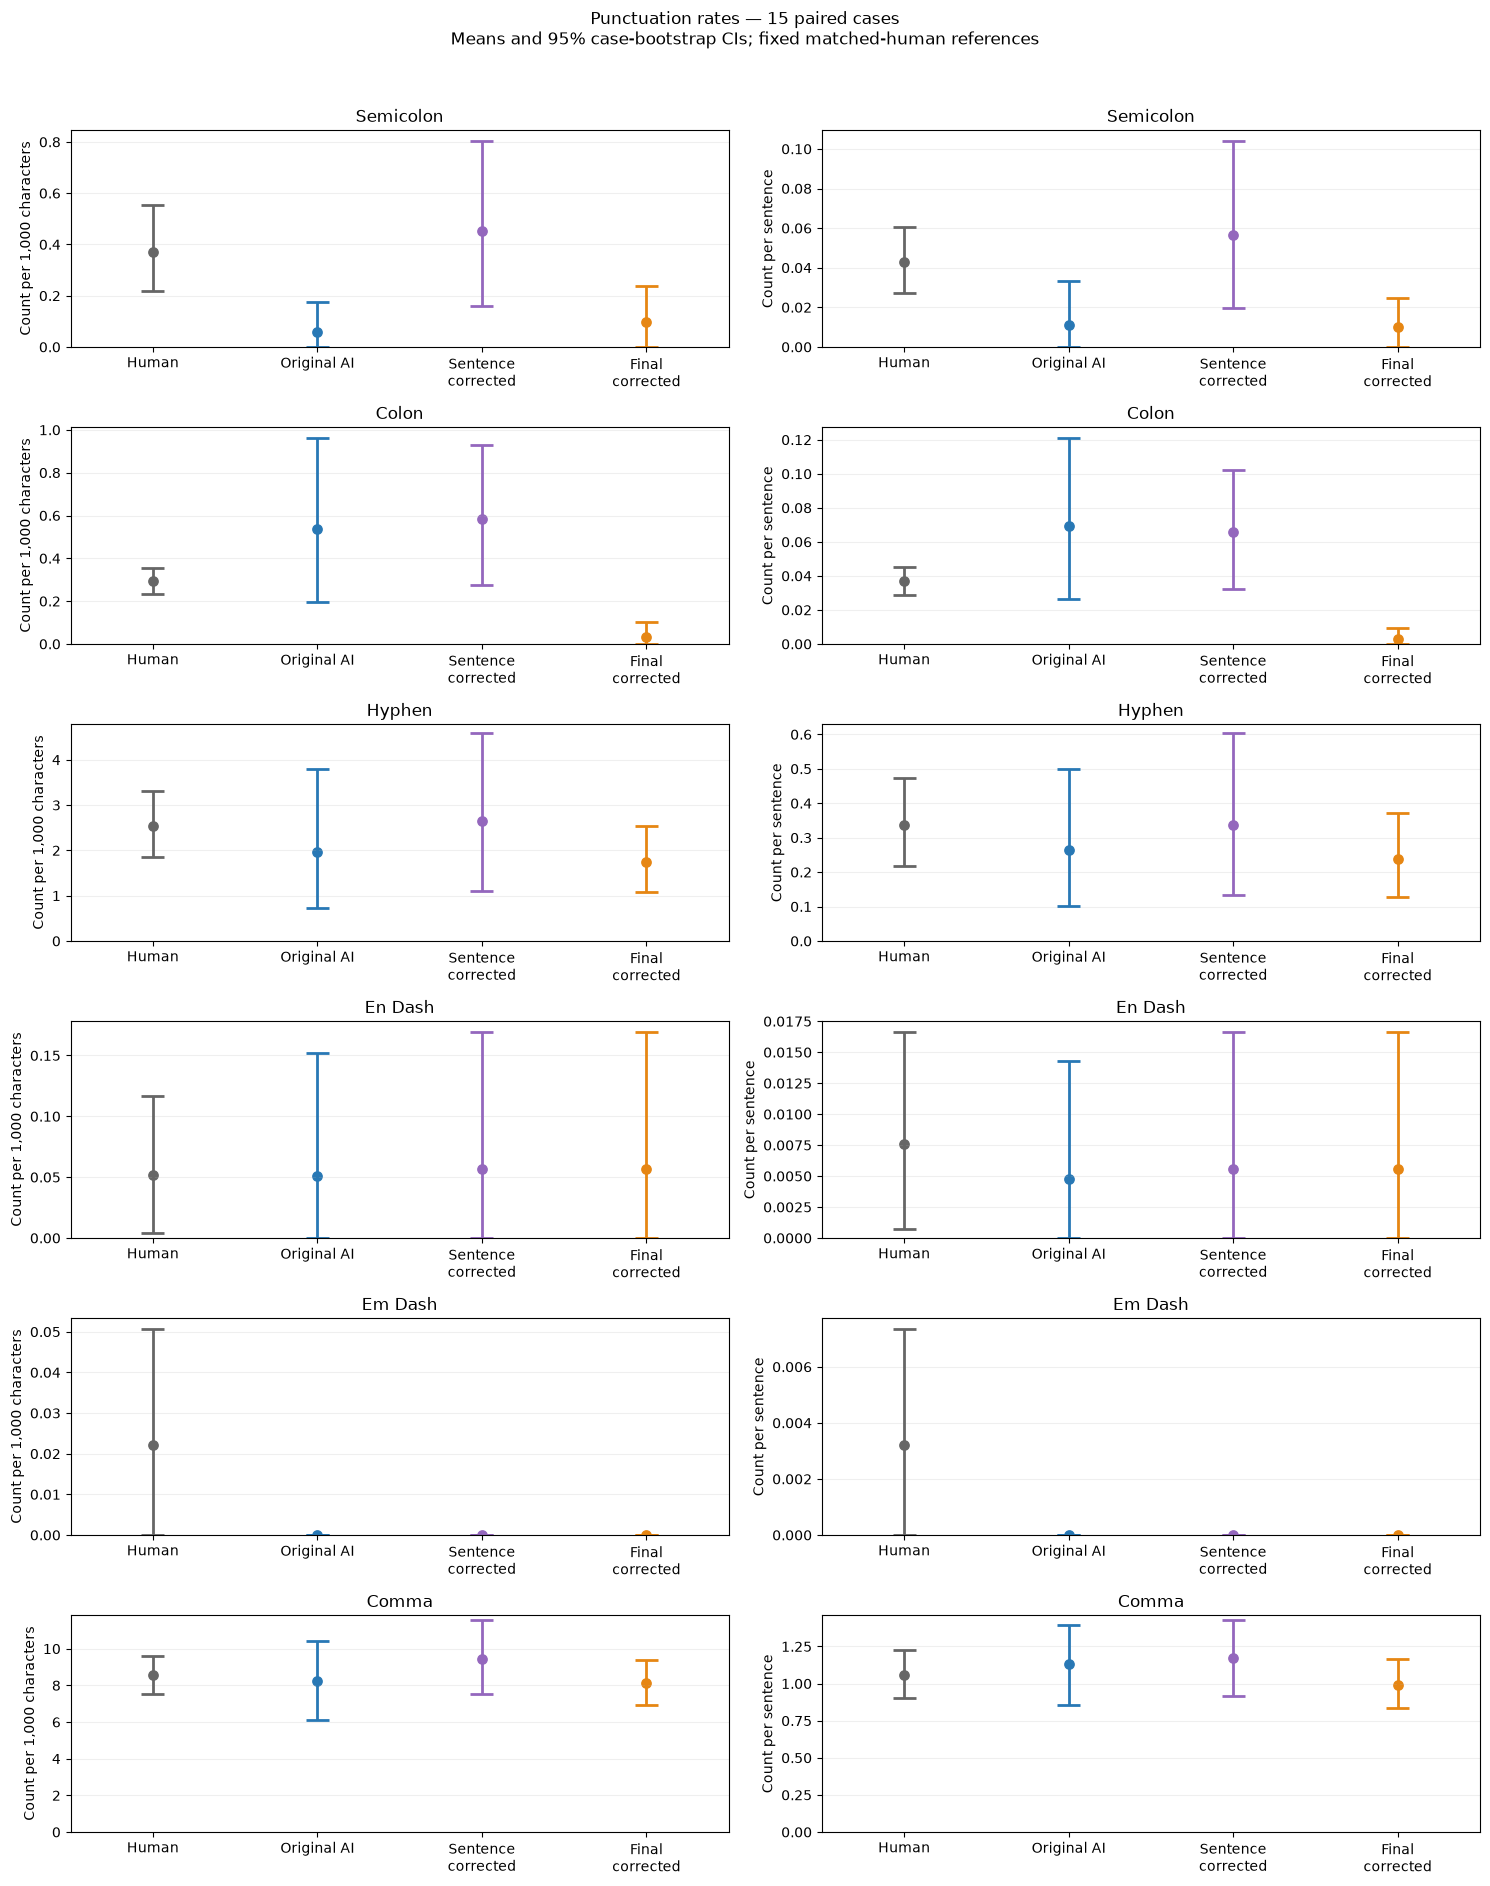

,human_zero,original_zero,intermediate_zero,final_zero
mark,,,,
semicolon,0.766,0.933,0.600,0.867
colon,0.758,0.533,0.467,0.933
hyphen,0.196,0.333,0.200,0.133
en_dash,0.956,0.933,0.933,0.933
em_dash,0.982,1.000,1.000,1.000
comma,0.007,0.000,0.000,0.000


,mark,denominator,comparison,mean_difference,ci_low,ci_high
0,semicolon,relative,Final minus Human,-0.000273,-0.000411,-0.000141
1,semicolon,relative,Final minus Original,0.000040,-0.000133,0.000210
2,semicolon,relative,Final minus Sentence-corrected,-0.000354,-0.000727,-0.000065
3,semicolon,per_sentence,Final minus Human,-0.032803,-0.051031,-0.016113
4,semicolon,per_sentence,Final minus Original,-0.001221,-0.028571,0.020147
5,semicolon,per_sentence,Final minus Sentence-corrected,-0.046419,-0.096156,-0.007843
6,colon,relative,Final minus Human,-0.000259,-0.000307,-0.000206
7,colon,relative,Final minus Original,-0.000502,-0.000867,-0.000193
8,colon,relative,Final minus Sentence-corrected,-0.000551,-0.000854,-0.000268
9,colon,per_sentence,Final minus Human,-0.033864,-0.042928,-0.025109


condition,final_corrected,original_ai,sentence_corrected,punctuation_change
case_id,,,,
raid_residual_03,0.657262,0.738410,0.477969,0.179293
raid_residual_05,0.541442,0.690588,0.660272,-0.118830
raid_residual_09,0.458832,0.615964,0.452777,0.006055
raid_residual_10,0.345279,0.587977,0.361022,-0.015743
raid_residual_14,0.504257,0.518635,0.507570,-0.003313
raid_residual_16,0.563365,0.622155,0.563365,0.000000
raid_residual_17,0.456401,0.569749,0.404901,0.051499
raid_residual_18,0.498557,0.526377,0.326342,0.172215
raid_residual_19,0.451518,0.548499,0.500481,-0.048963


,original_gap,before_punctuation_gap,final_gap,ci_low,ci_high,fraction_AIward,before_rank,final_rank
punct_relative_semicolon,0.010539,-0.008234,0.007062,-0.000480,0.012698,0.866667,114,1
pos_1gram_overlap_bin_9,0.002865,0.006694,0.007055,0.001959,0.012169,0.733333,5,2
pos_3gram_overlap_bin_0,0.008638,0.005625,0.006588,0.002407,0.010395,0.933333,10,3
share_long_words,0.003740,0.005650,0.006423,0.003147,0.010036,0.800000,9,4
punct_per_sentence_period,0.004446,0.006527,0.006256,0.002500,0.009327,0.800000,7,5
pos_1gram_overlap_bin_5,0.003536,0.005283,0.006063,0.003082,0.009362,0.866667,14,6
share_google_top100,0.009169,0.006634,0.005905,0.001398,0.010875,0.733333,6,7
pos_2gram_overlap_bin_1,0.005520,0.005412,0.005905,0.002858,0.008626,0.933333,13,8
punct_relative_exclamation,0.005419,0.005426,0.005615,0.000074,0.012094,0.666667,12,9
words_per_sentence,0.001926,0.005569,0.005572,0.003960,0.007242,0.933333,11,10


,original_gap,before_punctuation_gap,final_gap,ci_low,ci_high,fraction_AIward,before_rank,final_rank
share_unique_words,0.025498,0.004471,0.003783,-0.0006,0.008975,0.533333,22,28


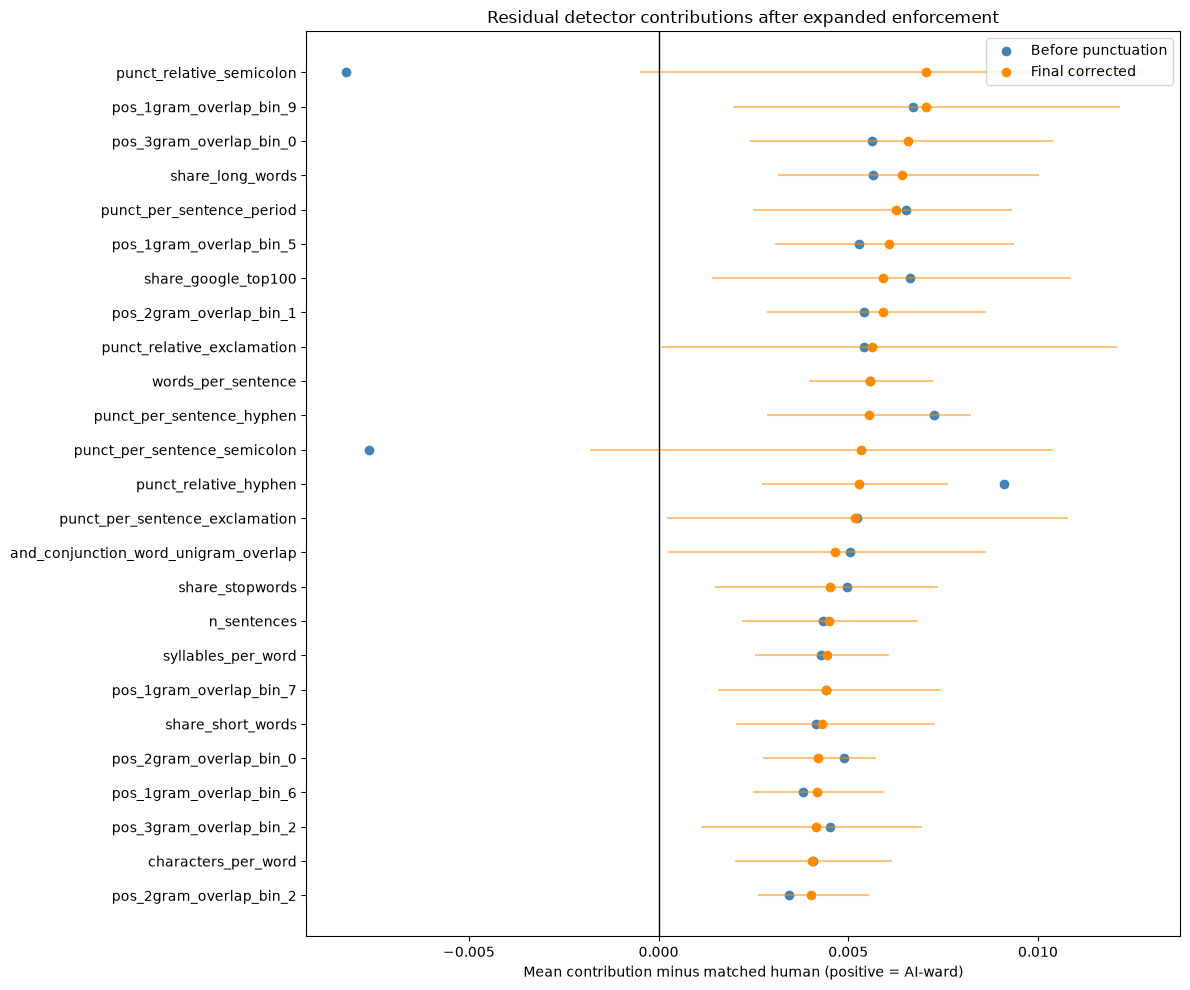

Saved evaluation: ../results/causal/C02q_vertex_search/evaluation
Text quality requires your review of the displayed edits.
CIs are conditional on these selected cases and fixed human pools; they are not acceptance bands or proof of distributional equivalence.


In [18]:
# Review and evaluate the latest expanded punctuation outputs.
import difflib
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

EVAL_OUT = PUNCT_OUT / "evaluation"
EVAL_OUT.mkdir(parents=True, exist_ok=True)

assert punct_results, "Run the latest enforcement cell first."
evaluation_results = list(punct_results)
case_ids = [case["case_id"] for case, text in evaluation_results]
assert len(case_ids) == len(set(case_ids))

# ------------------------------------------------------------
# 1. Show changed passages and verify hard invariants.
# ------------------------------------------------------------
review_rows = []

for case, corrected in evaluation_results:
    before = case["text"]  # Sentence-corrected, before punctuation editing.
    before_stats, _ = measure(nlp(normalize(before)))
    after_stats, _ = measure(nlp(normalize(corrected)))

    row = dict(
        case_id=case["case_id"],
        changed=before != corrected,
        periods_preserved=before.count(".") == corrected.count("."),
        sentences_preserved=before_stats["S"] == after_stats["S"],
        questions_preserved=before.count("?") == corrected.count("?"),
        exclamations_preserved=before.count("!") == corrected.count("!"),
        wps_change=after_stats["wps_mean"] - before_stats["wps_mean"],
        cps_change=after_stats["cps_mean"] - before_stats["cps_mean"],
        unique_change=(
            after_stats["share_unique_words"]
            - before_stats["share_unique_words"]
        ),
        before=before,
        after=corrected,
    )
    review_rows.append(row)

    if before != corrected:
        if "show_local_diff" in globals():
            show_local_diff(before, corrected, case["case_id"])
        else:
            display(HTML(
                '<div style="white-space:pre-wrap;overflow-wrap:anywhere;'
                'margin:16px 0">'
                f"<b>{html.escape(case['case_id'])}</b><br>"
                f"<b>Before:</b><br>{html.escape(before)}<br><br>"
                f"<b>After:</b><br>{html.escape(corrected)}</div>"
            ))

review_table = pd.DataFrame(review_rows)
hard_checks = [
    "periods_preserved", "sentences_preserved",
    "questions_preserved", "exclamations_preserved"
]
assert review_table[hard_checks].all().all(), (
    "A hard invariant failed. Inspect review_table before interpreting results."
)
display(review_table.drop(columns=["before", "after"]).round(5))
review_table.to_csv(EVAL_OUT / "text_and_invariant_review.csv", index=False)

manual_path = EVAL_OUT / "manual_review.csv"
if not manual_path.exists():
    review_table.assign(
        grammar_acceptable="", meaning_preserved="", notes=""
    ).to_csv(manual_path, index=False)

# Audit all accepted edits for unintended changes to other nontrivial marks.
cross_mark_rows = []
if "expanded_edits" in globals():
    for edit in expanded_edits:
        changed_other = {
            mark: (
                edit["after_text"].count(PMARKS[mark])
                - edit["before_text"].count(PMARKS[mark])
            )
            for mark in nontrivial_marks
            if mark != edit["mark"]
            and edit["after_text"].count(PMARKS[mark])
            != edit["before_text"].count(PMARKS[mark])
        }
        if changed_other:
            cross_mark_rows.append(dict(
                case_id=edit["case_id"],
                target_mark=edit["mark"],
                rule=edit["rule"],
                other_count_changes=str(changed_other)
            ))

    print("\nCase 10 hyphen edit history:")
    for edit in expanded_edits:
        if edit["case_id"] == "raid_residual_10":
            old_count = edit["before_text"].count("-")
            new_count = edit["after_text"].count("-")
            if old_count != new_count:
                print(
                    edit["mark"], edit["rule"],
                    f"| hyphens {old_count} → {new_count}"
                )

print("Cross-mark count violations:", len(cross_mark_rows))
if cross_mark_rows:
    display(pd.DataFrame(cross_mark_rows))

# ------------------------------------------------------------
# 2. Human / original / sentence-corrected / final punctuation CIs.
# The extra intermediate condition isolates punctuation editing.
# ------------------------------------------------------------
conditions = [
    "Human", "Original AI", "Sentence-corrected", "Final corrected"
]
marks = list(PMARKS)
denominators = ["relative", "per_sentence"]
manifest_index = manifest.set_index("case_id")
assert manifest_index.index.is_unique

rate_cache = {}

def cached_rates(source_id):
    if source_id not in rate_cache:
        text = normalize(text_map[source_id])
        rate_cache[source_id] = (
            punct_values(text),
            {mark: text.count(symbol) for mark, symbol in PMARKS.items()}
        )
    return rate_cache[source_id]

ci_rows = []
for case, corrected in evaluation_results:
    original_id = manifest_index.loc[case["case_id"], "source_id"]
    original_rates, original_counts = cached_rates(original_id)
    intermediate = normalize(case["text"])
    corrected = normalize(corrected)
    intermediate_rates = punct_values(intermediate)
    final_rates = punct_values(corrected)
    refs = [cached_rates(source_id) for source_id in case["reference_ids"]]

    for mark in marks:
        for denominator in denominators:
            key = (mark, denominator)
            ci_rows.append(dict(
                case_id=case["case_id"],
                mark=mark,
                denominator=denominator,
                **{
                    "Human": np.mean([rates[key] for rates, counts in refs]),
                    "Original AI": original_rates[key],
                    "Sentence-corrected": intermediate_rates[key],
                    "Final corrected": final_rates[key],
                },
                human_zero=np.mean([
                    counts[mark] == 0 for rates, counts in refs
                ]),
                original_zero=float(original_counts[mark] == 0),
                intermediate_zero=float(intermediate.count(PMARKS[mark]) == 0),
                final_zero=float(corrected.count(PMARKS[mark]) == 0),
            ))

ci_cases = pd.DataFrame(ci_rows)
rng = np.random.default_rng(2026)
draws = rng.integers(0, len(case_ids), size=(5000, len(case_ids)))
summary_rows, difference_rows = [], []

for mark in marks:
    for denominator in denominators:
        block = (
            ci_cases.loc[
                (ci_cases.mark == mark)
                & (ci_cases.denominator == denominator)
            ]
            .set_index("case_id").loc[case_ids, conditions]
        )
        values = block.to_numpy(float)
        assert np.isfinite(values).all()
        boot = values[draws].mean(axis=1)

        for j, condition in enumerate(conditions):
            low, high = np.quantile(boot[:, j], [.025, .975])
            summary_rows.append(dict(
                mark=mark, denominator=denominator, condition=condition,
                mean=values[:, j].mean(), ci_low=low, ci_high=high
            ))

        for label, left, right in [
            ("Final minus Human", 3, 0),
            ("Final minus Original", 3, 1),
            ("Final minus Sentence-corrected", 3, 2),
        ]:
            low, high = np.quantile(
                boot[:, left] - boot[:, right], [.025, .975]
            )
            difference_rows.append(dict(
                mark=mark, denominator=denominator, comparison=label,
                mean_difference=(values[:, left] - values[:, right]).mean(),
                ci_low=low, ci_high=high
            ))

ci_summary = pd.DataFrame(summary_rows)
ci_differences = pd.DataFrame(difference_rows)
colors = ["#666666", "#2878B5", "#9467BD", "#E68613"]

fig, axes = plt.subplots(len(marks), 2, figsize=(15, 3.2 * len(marks)))
for i, mark in enumerate(marks):
    for j, denominator in enumerate(denominators):
        ax = axes[i, j]
        panel = (
            ci_summary.loc[
                (ci_summary.mark == mark)
                & (ci_summary.denominator == denominator)
            ]
            .set_index("condition").loc[conditions]
        )
        scale = 1000 if denominator == "relative" else 1
        for x, condition in enumerate(conditions):
            row = panel.loc[condition]
            low, high = row.ci_low * scale, row.ci_high * scale
            ax.vlines(x, low, high, color=colors[x], lw=2)
            ax.hlines([low, high], x-.07, x+.07, color=colors[x], lw=2)
            ax.scatter(x, row["mean"] * scale, color=colors[x], s=45)
        ax.set_xticks(range(4), [
            "Human", "Original AI", "Sentence\ncorrected", "Final\ncorrected"
        ])
        ax.set_xlim(-.5, 3.5)
        ax.set_ylim(bottom=0)
        ax.set_title(mark.replace("_", " ").title())
        ax.set_ylabel(
            "Count per 1,000 characters"
            if denominator == "relative" else "Count per sentence"
        )
        ax.grid(axis="y", alpha=.2)

fig.suptitle(
    f"Punctuation rates — {len(case_ids)} paired cases\n"
    "Means and 95% case-bootstrap CIs; fixed matched-human references"
)
fig.tight_layout(rect=[0, 0, 1, .965])
fig.savefig(EVAL_OUT / "punctuation_CIs.png", dpi=180, bbox_inches="tight")
plt.show()

zero_use = (
    ci_cases.loc[ci_cases.denominator == "relative"]
    .groupby("mark")[
        ["human_zero", "original_zero", "intermediate_zero", "final_zero"]
    ].mean().reindex(marks)
)
display(zero_use.round(3))
display(ci_differences.round(6))
ci_cases.to_csv(EVAL_OUT / "punctuation_CI_cases.csv", index=False)
ci_summary.to_csv(EVAL_OUT / "punctuation_CI_summary.csv", index=False)
ci_differences.to_csv(EVAL_OUT / "punctuation_CI_differences.csv", index=False)
zero_use.to_csv(EVAL_OUT / "zero_use_fractions.csv")

# ------------------------------------------------------------
# 3. Residual frozen-detector contribution ranking.
# Recompute human contributions using the same extractor.
# ------------------------------------------------------------
human_ids = sorted({
    source_id
    for case, text in evaluation_results
    for source_id in case["reference_ids"]
})
human_vectors = pd.DataFrame(
    [extract_fz118(normalize(text_map[sid])) for sid in human_ids],
    index=human_ids, columns=FEATURE_NAMES
)
human_accounting = pd.DataFrame(
    contributions(human_vectors[model_features]),
    index=human_ids, columns=model_features
)

records, vectors = [], []
for case, corrected in evaluation_results:
    original_id = manifest_index.loc[case["case_id"], "source_id"]
    for condition, text in [
        ("original_ai", text_map[original_id]),
        ("sentence_corrected", case["text"]),
        ("final_corrected", corrected),
    ]:
        records.append(dict(case_id=case["case_id"], condition=condition))
        vectors.append(extract_fz118(normalize(text)))

index = pd.MultiIndex.from_frame(pd.DataFrame(records))
evaluation_features = pd.DataFrame(
    vectors, index=index, columns=FEATURE_NAMES
)
evaluation_contributions = pd.DataFrame(
    contributions(evaluation_features[model_features]),
    index=index, columns=model_features
)
scores = pd.Series(
    detector.predict_proba(evaluation_features[model_features])[:, 1],
    index=index
).unstack("condition")
scores["punctuation_change"] = (
    scores.final_corrected - scores.sentence_corrected
)
display(scores.round(6))

gaps = {}
for condition in ["original_ai", "sentence_corrected", "final_corrected"]:
    gaps[condition] = pd.DataFrame([
        evaluation_contributions.loc[(case["case_id"], condition)].values
        - human_accounting.loc[case["reference_ids"]].mean().values
        for case, text in evaluation_results
    ], index=case_ids, columns=model_features)

final_values = gaps["final_corrected"].to_numpy()
# Batch bootstrap to avoid a large cases × resamples × features allocation.
bootstrap_final = np.concatenate([
    final_values[batch].mean(axis=1)
    for batch in np.array_split(draws, 20)
])

ranking = pd.DataFrame({
    "original_gap": gaps["original_ai"].mean(),
    "before_punctuation_gap": gaps["sentence_corrected"].mean(),
    "final_gap": gaps["final_corrected"].mean(),
    "ci_low": np.quantile(bootstrap_final, .025, axis=0),
    "ci_high": np.quantile(bootstrap_final, .975, axis=0),
    "fraction_AIward": (gaps["final_corrected"] > 0).mean(),
})
ranking["before_rank"] = ranking.before_punctuation_gap.rank(
    ascending=False, method="min"
).astype(int)
ranking = ranking.sort_values("final_gap", ascending=False)
ranking["final_rank"] = np.arange(1, len(ranking) + 1)

display(ranking.head(25).round(6))
if "share_unique_words" in ranking.index:
    display(ranking.loc[["share_unique_words"]].round(6))

top = ranking.head(25).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(12, 10))
ax.hlines(y, top.ci_low, top.ci_high, color="darkorange", alpha=.5)
ax.scatter(
    top.before_punctuation_gap, y,
    color="steelblue", label="Before punctuation"
)
ax.scatter(top.final_gap, y, color="darkorange", label="Final corrected")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y, top.index)
ax.set_xlabel("Mean contribution minus matched human (positive = AI-ward)")
ax.set_title("Residual detector contributions after expanded enforcement")
ax.legend()
fig.tight_layout()
fig.savefig(EVAL_OUT / "residual_ranking.png", dpi=180, bbox_inches="tight")
plt.show()

evaluation_features.to_csv(EVAL_OUT / "feature_values.csv")
evaluation_contributions.to_csv(EVAL_OUT / "contributions.csv")
scores.to_csv(EVAL_OUT / "detector_scores.csv")
ranking.to_csv(EVAL_OUT / "residual_ranking.csv")

print("Saved evaluation:", EVAL_OUT)
print("Text quality requires your review of the displayed edits.")
print(
    "CIs are conditional on these selected cases and fixed human pools; "
    "they are not acceptance bands or proof of distributional equivalence."
)